# Estudo de Ablação por Troca de Módulos no iTransformer (ICLR 2024)

**Disciplina:** Aprendizado de Máquina Profundo — UFSM (Prof. Thiago L. T. da Silveira)  
**Artigo:** *iTransformer: Inverted Transformers Are Effective for Time Series Forecasting* (Liu et al., ICLR 2024, [arXiv:2310.06625](https://arxiv.org/abs/2310.06625))  
**Repositório oficial fixado:** `thuml/iTransformer` @ commit `c2426e68ca13f74aaec08045c5c724d8ad328124`

---

## Instruções de Execução

### No Kaggle (Recomendado)
1. Faça upload deste notebook (`iTransformer_ablation.ipynb`) em **New Notebook**.
2. Em **Settings** (painel direito):
   - **Accelerator:** `GPU T4 x2` ou `GPU P100` (o script usa 1 GPU automaticamente).
   - **Internet:** `On` (necessário para clonar o repositório e baixar os dados).
   - **Persistence:** `Files only` (ou baixe a pasta `/kaggle/working/itransformer_ablation_out` ao final).
3. Na **Célula 5**, defina `QUICK = False` para o experimento completo (54 treinos) ou mantenha `QUICK = True` para um *smoke test* rápido (1 época, 1 seed, 18 treinos).
4. Execute **Run All**. Em caso de desconexão, basta rodar novamente: a Célula 6 **retoma automaticamente** a partir do arquivo JSONL salvo em `/kaggle/working/itransformer_ablation_out/`.

### No Google Colab Pro
1. Abra o notebook no Colab e selecione **Runtime → Change runtime type → GPU** (T4, L4 ou A100).
2. A Célula 2 monta o Google Drive automaticamente e salva todos os resultados em `/content/drive/MyDrive/itransformer_ablation_out/` (permitindo retomada mesmo após desconexão).
3. Ajuste `QUICK = False` na Célula 5 e execute **Run all**.

---

## Resumo das 9 Configurações Avaliadas

| ID | Família | Modificação aplicada |
|---|---|---|
| `baseline` | — | iTransformer original (referência) |
| `attn_none` | Atenção entre variáveis | Remove o subbloco de atenção (sem mistura entre tokens) |
| `attn_linear` | Atenção entre variáveis | Mistura linear estática: $\mathrm{out} = W_o \cdot M \cdot (X W_v)$, $M \in \mathbb{R}^{N_{\text{tok}} \times N_{\text{tok}}}$ aprendida e independente da entrada |
| `norm_batch` | Normalização da representação | `LayerNorm` $\to$ `BatchNorm1d(d_model)` aplicada sobre $(B \cdot N_{\text{tok}})$ tokens (`norm1`, `norm2` e `norm_layer` final) |
| `norm_none` | Normalização da representação | `LayerNorm` $\to$ `Identity` (`norm1`, `norm2` e `norm_layer` final) |
| `revin_none` | Normalização de instância | Desliga normalização/desnormalização por série (`use_norm=0`, `revin=none`) |
| `revin_center` | Normalização de instância | Apenas subtrai a média por série e soma de volta (sem dividir pelo desvio-padrão) |
| `ffn_linear` | FFN | Substitui `Conv1d(k=1) -> GELU -> Conv1d(k=1)` por uma única `nn.Linear(d_model, d_model)` sem não linearidade |
| `no_residual` | Conexões residuais | Remove as duas conexões residuais da camada do codificador (`x = sublayer(x)`) |


In [1]:
# === CÉLULA 2: Setup (Ambiente, GPU, Clone no Commit Fixado e Dependências Mínimas) ===
import os
import sys
import subprocess
import importlib.util
from pathlib import Path

# 1. Detecção de ambiente (Kaggle / Colab / Local)
IN_KAGGLE = os.path.exists("/kaggle/working")
IN_COLAB = "google.colab" in sys.modules

if IN_KAGGLE:
    ENV_NAME = "Kaggle"
    BASE_DIR = Path("/kaggle/working")
    OUT_DIR = BASE_DIR / "itransformer_ablation_out"
elif IN_COLAB:
    ENV_NAME = "Colab"
    BASE_DIR = Path("/content")
    try:
        from google.colab import drive
        drive.mount("/content/drive", force_remount=False)
        OUT_DIR = Path("/content/drive/MyDrive/itransformer_ablation_out")
    except Exception as e:
        print(f"[AVISO] Não foi possível montar o Google Drive ({e}). Salvando em /content.")
        OUT_DIR = BASE_DIR / "itransformer_ablation_out"
else:
    ENV_NAME = "Local"
    BASE_DIR = Path.cwd()
    OUT_DIR = BASE_DIR / "ablation_outputs"

REPO_DIR = BASE_DIR / "iTransformer"
OUT_DIR.mkdir(parents=True, exist_ok=True)
PINNED_COMMIT = "c2426e68ca13f74aaec08045c5c724d8ad328124"

print(f"Ambiente detectado: {ENV_NAME}")
print(f"Python: {sys.version.split()[0]} ({sys.executable})")
print(f"Diretório do repositório: {REPO_DIR}")
print(f"Diretório de saída persistente: {OUT_DIR}")

# 2. Detecção de GPU (SEM reinstalar torch!)
import torch
import numpy as np

print(f"PyTorch: {torch.__version__} | NumPy: {np.__version__}")
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    gpu_mem = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"GPU disponível: {gpu_name} ({gpu_mem:.1f} GB VRAM)")
else:
    print("GPU não detectada — executando em CPU.")

# 3. Instalação mínima apenas do que faltar (NUNCA reinstala torch nem numpy)
REQUIRED_PKGS = [
    ("einops", "einops"),
    ("reformer_pytorch", "reformer-pytorch"),
    ("gdown", "gdown"),
    ("sklearn", "scikit-learn"),
    ("pandas", "pandas"),
    ("matplotlib", "matplotlib"),
    ("scipy", "scipy"),
]

missing = [pip_name for mod_name, pip_name in REQUIRED_PKGS if importlib.util.find_spec(mod_name) is None]
if missing:
    print(f"Instalando apenas pacotes ausentes (preservando torch): {missing}")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "--upgrade-strategy", "only-if-needed", *missing
    ])
else:
    print("Todas as dependências mínimas já estão instaladas.")

# Confirma que o torch do ambiente foi preservado
import reformer_pytorch  # noqa: F401
print(f"Verificação pós-setup: torch={torch.__version__}, reformer_pytorch OK.")

# 4. Clone do repositório oficial no commit fixado
if not (REPO_DIR / ".git").exists():
    print(f"Clonando thuml/iTransformer em {REPO_DIR}...")
    subprocess.check_call(["git", "clone", "https://github.com/thuml/iTransformer.git", str(REPO_DIR)])

subprocess.check_call(["git", "fetch", "--all", "--quiet"], cwd=str(REPO_DIR))
subprocess.check_call(["git", "checkout", "--force", PINNED_COMMIT], cwd=str(REPO_DIR))
head_hash = subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=str(REPO_DIR), text=True).strip()
assert head_hash == PINNED_COMMIT, f"Commit inesperado: {head_hash}"
print(f"Repositório posicionado no commit fixado: {head_hash}")


Ambiente detectado: Local
Python: 3.12.10 (C:\Users\oandr\Documentos computador\t_final_ml\.venv\Scripts\python.exe)
Diretório do repositório: C:\Users\oandr\Documentos computador\t_final_ml\iTransformer
Diretório de saída persistente: C:\Users\oandr\Documentos computador\t_final_ml\ablation_outputs


PyTorch: 2.15.0+cpu | NumPy: 2.5.5
GPU não detectada — executando em CPU.
Todas as dependências mínimas já estão instaladas.
Verificação pós-setup: torch=2.15.0+cpu, reformer_pytorch OK.


Repositório posicionado no commit fixado: c2426e68ca13f74aaec08045c5c724d8ad328124


In [2]:
# === CÉLULA 3A: Aplicação Autocontida das Modificações (git apply) ===
import subprocess
from pathlib import Path

PATCH_CONTENT = 'diff --git a/experiments/exp_long_term_forecasting.py b/experiments/exp_long_term_forecasting.py\nindex 35170c6..a3e6020 100644\n--- a/experiments/exp_long_term_forecasting.py\n+++ b/experiments/exp_long_term_forecasting.py\n@@ -16,6 +16,7 @@ warnings.filterwarnings(\'ignore\')\n class Exp_Long_Term_Forecast(Exp_Basic):\n     def __init__(self, args):\n         super(Exp_Long_Term_Forecast, self).__init__(args)\n+        self.epoch_times = []  # [MOD]\n \n     def _build_model(self):\n         model = self.model_dict[self.args.model].Model(self.args).float()\n@@ -82,13 +83,16 @@ class Exp_Long_Term_Forecast(Exp_Basic):\n     def train(self, setting):\n         train_data, train_loader = self._get_data(flag=\'train\')\n         vali_data, vali_loader = self._get_data(flag=\'val\')\n-        test_data, test_loader = self._get_data(flag=\'test\')\n+        skip_test = getattr(self.args, \'skip_test_during_train\', False)  # [MOD]\n+        if not skip_test:  # [MOD]\n+            test_data, test_loader = self._get_data(flag=\'test\')  # [MOD]\n \n         path = os.path.join(self.args.checkpoints, setting)\n         if not os.path.exists(path):\n             os.makedirs(path)\n \n         time_now = time.time()\n+        self.epoch_times = []  # [MOD]\n \n         train_steps = len(train_loader)\n         early_stopping = EarlyStopping(patience=self.args.patience, verbose=True)\n@@ -162,13 +166,18 @@ class Exp_Long_Term_Forecast(Exp_Basic):\n                     loss.backward()\n                     model_optim.step()\n \n-            print("Epoch: {} cost time: {}".format(epoch + 1, time.time() - epoch_time))\n+            epoch_cost = time.time() - epoch_time  # [MOD]\n+            self.epoch_times.append(epoch_cost)  # [MOD]\n+            print("Epoch: {} cost time: {}".format(epoch + 1, epoch_cost))  # [MOD]\n             train_loss = np.average(train_loss)\n             vali_loss = self.vali(vali_data, vali_loader, criterion)\n-            test_loss = self.vali(test_data, test_loader, criterion)\n-\n-            print("Epoch: {0}, Steps: {1} | Train Loss: {2:.7f} Vali Loss: {3:.7f} Test Loss: {4:.7f}".format(\n-                epoch + 1, train_steps, train_loss, vali_loss, test_loss))\n+            if not skip_test:  # [MOD]\n+                test_loss = self.vali(test_data, test_loader, criterion)  # [MOD]\n+                print("Epoch: {0}, Steps: {1} | Train Loss: {2:.7f} Vali Loss: {3:.7f} Test Loss: {4:.7f}".format(  # [MOD]\n+                    epoch + 1, train_steps, train_loss, vali_loss, test_loss))  # [MOD]\n+            else:  # [MOD]\n+                print("Epoch: {0}, Steps: {1} | Train Loss: {2:.7f} Vali Loss: {3:.7f}".format(  # [MOD]\n+                    epoch + 1, train_steps, train_loss, vali_loss))  # [MOD]\n             early_stopping(vali_loss, self.model, path)\n             if early_stopping.early_stop:\n                 print("Early stopping")\n@@ -179,7 +188,7 @@ class Exp_Long_Term_Forecast(Exp_Basic):\n             # get_cka(self.args, setting, self.model, train_loader, self.device, epoch)\n \n         best_model_path = path + \'/\' + \'checkpoint.pth\'\n-        self.model.load_state_dict(torch.load(best_model_path))\n+        self.model.load_state_dict(torch.load(best_model_path, map_location=self.device))  # [MOD]\n \n         return self.model\n \n@@ -187,12 +196,14 @@ class Exp_Long_Term_Forecast(Exp_Basic):\n         test_data, test_loader = self._get_data(flag=\'test\')\n         if test:\n             print(\'loading model\')\n-            self.model.load_state_dict(torch.load(os.path.join(\'./checkpoints/\' + setting, \'checkpoint.pth\')))\n+            self.model.load_state_dict(torch.load(os.path.join(\'./checkpoints/\' + setting, \'checkpoint.pth\'), map_location=self.device))  # [MOD]\n \n         preds = []\n         trues = []\n+        skip_visual = getattr(self.args, \'skip_visual\', False)  # [MOD]\n+        skip_save_npy = getattr(self.args, \'skip_save_npy\', False)  # [MOD]\n         folder_path = \'./test_results/\' + setting + \'/\'\n-        if not os.path.exists(folder_path):\n+        if not skip_visual and not os.path.exists(folder_path):  # [MOD]\n             os.makedirs(folder_path)\n \n         self.model.eval()\n@@ -240,7 +251,7 @@ class Exp_Long_Term_Forecast(Exp_Basic):\n \n                 preds.append(pred)\n                 trues.append(true)\n-                if i % 20 == 0:\n+                if not skip_visual and i % 20 == 0:  # [MOD]\n                     input = batch_x.detach().cpu().numpy()\n                     if test_data.scale and self.args.inverse:\n                         shape = input.shape\n@@ -256,25 +267,25 @@ class Exp_Long_Term_Forecast(Exp_Basic):\n         trues = trues.reshape(-1, trues.shape[-2], trues.shape[-1])\n         print(\'test shape:\', preds.shape, trues.shape)\n \n-        # result save\n-        folder_path = \'./results/\' + setting + \'/\'\n-        if not os.path.exists(folder_path):\n-            os.makedirs(folder_path)\n-\n         mae, mse, rmse, mape, mspe = metric(preds, trues)\n         print(\'mse:{}, mae:{}\'.format(mse, mae))\n-        f = open("result_long_term_forecast.txt", \'a\')\n-        f.write(setting + "  \\n")\n-        f.write(\'mse:{}, mae:{}\'.format(mse, mae))\n-        f.write(\'\\n\')\n-        f.write(\'\\n\')\n-        f.close()\n-\n-        np.save(folder_path + \'metrics.npy\', np.array([mae, mse, rmse, mape, mspe]))\n-        np.save(folder_path + \'pred.npy\', preds)\n-        np.save(folder_path + \'true.npy\', trues)\n-\n-        return\n+        if not skip_save_npy:  # [MOD]\n+            # result save  # [MOD]\n+            folder_path = \'./results/\' + setting + \'/\'  # [MOD]\n+            if not os.path.exists(folder_path):  # [MOD]\n+                os.makedirs(folder_path)  # [MOD]\n+            f = open("result_long_term_forecast.txt", \'a\')  # [MOD]\n+            f.write(setting + "  \\n")  # [MOD]\n+            f.write(\'mse:{}, mae:{}\'.format(mse, mae))  # [MOD]\n+            f.write(\'\\n\')  # [MOD]\n+            f.write(\'\\n\')  # [MOD]\n+            f.close()  # [MOD]\n+\n+            np.save(folder_path + \'metrics.npy\', np.array([mae, mse, rmse, mape, mspe]))  # [MOD]\n+            np.save(folder_path + \'pred.npy\', preds)  # [MOD]\n+            np.save(folder_path + \'true.npy\', trues)  # [MOD]\n+\n+        return float(mse), float(mae)  # [MOD]\n \n \n     def predict(self, setting, load=False):\ndiff --git a/layers/Ablation.py b/layers/Ablation.py\nnew file mode 100644\nindex 0000000..598c0e2\n--- /dev/null\n+++ b/layers/Ablation.py\n@@ -0,0 +1,112 @@\n+# [MOD] New module implementing ablation components for iTransformer\n+import torch  # [MOD]\n+import torch.nn as nn  # [MOD]\n+import torch.nn.functional as F  # [MOD]\n+\n+\n+class TokenBatchNorm(nn.Module):  # [MOD]\n+    """Applies BatchNorm1d(d_model) across all (B * N) variate tokens."""  # [MOD]\n+\n+    def __init__(self, d_model):  # [MOD]\n+        super(TokenBatchNorm, self).__init__()  # [MOD]\n+        self.bn = nn.BatchNorm1d(d_model)  # [MOD]\n+\n+    def forward(self, x):  # [MOD]\n+        # x: [B, N, E] -> [B * N, E] -> [B, N, E]  # [MOD]\n+        B, N, E = x.shape  # [MOD]\n+        x = self.bn(x.reshape(B * N, E))  # [MOD]\n+        return x.reshape(B, N, E)  # [MOD]\n+\n+\n+def make_norm(norm_type, d_model):  # [MOD]\n+    """Factory for normalization layers: layer, batch, or none."""  # [MOD]\n+    if norm_type == "layer":  # [MOD]\n+        return nn.LayerNorm(d_model)  # [MOD]\n+    elif norm_type == "batch":  # [MOD]\n+        return TokenBatchNorm(d_model)  # [MOD]\n+    elif norm_type == "none":  # [MOD]\n+        return nn.Identity()  # [MOD]\n+    else:  # [MOD]\n+        raise ValueError(f"Unsupported norm_type: {norm_type}")  # [MOD]\n+\n+\n+class LinearTokenMixer(nn.Module):  # [MOD]\n+    """Static linear token mixing (MLP-Mixer style): out = W_o * M * (X W_v).  # [MOD]\n+\n+    M in R^{N x N} is learned and input-independent.  # [MOD]\n+    Matches AttentionLayer forward signature: (queries, keys, values, attn_mask, tau, delta) -> (out, None).  # [MOD]\n+    """  # [MOD]\n+\n+    def __init__(self, n_tokens, d_model):  # [MOD]\n+        super(LinearTokenMixer, self).__init__()  # [MOD]\n+        self.n_tokens = n_tokens  # [MOD]\n+        self.value_projection = nn.Linear(d_model, d_model)  # [MOD]\n+        self.token_mix = nn.Linear(n_tokens, n_tokens, bias=False)  # [MOD]\n+        self.out_projection = nn.Linear(d_model, d_model)  # [MOD]\n+\n+    def forward(self, queries, keys, values, attn_mask=None, tau=None, delta=None):  # [MOD]\n+        # values: [B, N, E]  # [MOD]\n+        B, N, E = values.shape  # [MOD]\n+        if N != self.n_tokens:  # [MOD]\n+            raise ValueError(  # [MOD]\n+                f"LinearTokenMixer expected {self.n_tokens} tokens, got {N}."  # [MOD]\n+            )  # [MOD]\n+        v = self.value_projection(values)  # [B, N, E]  # [MOD]\n+        mixed = self.token_mix(v.transpose(1, 2)).transpose(1, 2)  # [B, N, E]  # [MOD]\n+        out = self.out_projection(mixed)  # [B, N, E]  # [MOD]\n+        return out, None  # [MOD]\n+\n+\n+class AblationEncoderLayer(nn.Module):  # [MOD]\n+    """Configurable EncoderLayer preserving exact parameter creation order of EncoderLayer in baseline mode."""  # [MOD]\n+\n+    def __init__(  # [MOD]\n+        self,  # [MOD]\n+        attention,  # [MOD]\n+        d_model,  # [MOD]\n+        d_ff=None,  # [MOD]\n+        dropout=0.1,  # [MOD]\n+        activation="relu",  # [MOD]\n+        norm_type="layer",  # [MOD]\n+        ffn_type="mlp",  # [MOD]\n+        residual=True,  # [MOD]\n+    ):  # [MOD]\n+        super(AblationEncoderLayer, self).__init__()  # [MOD]\n+        d_ff = d_ff or 4 * d_model  # [MOD]\n+        # Preserve exact initialization order: attention, conv1/conv2 (or linear), norm1, norm2  # [MOD]\n+        self.attention = attention  # [MOD]\n+        self.ffn_type = ffn_type  # [MOD]\n+        self.residual = bool(residual)  # [MOD]\n+        if ffn_type == "mlp":  # [MOD]\n+            self.conv1 = nn.Conv1d(in_channels=d_model, out_channels=d_ff, kernel_size=1)  # [MOD]\n+            self.conv2 = nn.Conv1d(in_channels=d_ff, out_channels=d_model, kernel_size=1)  # [MOD]\n+        elif ffn_type == "linear":  # [MOD]\n+            self.ffn_linear = nn.Linear(d_model, d_model)  # [MOD]\n+        else:  # [MOD]\n+            raise ValueError(f"Unsupported ffn_type: {ffn_type}")  # [MOD]\n+        self.norm1 = make_norm(norm_type, d_model)  # [MOD]\n+        self.norm2 = make_norm(norm_type, d_model)  # [MOD]\n+        self.dropout = nn.Dropout(dropout)  # [MOD]\n+        self.activation = F.relu if activation == "relu" else F.gelu  # [MOD]\n+\n+    def forward(self, x, attn_mask=None, tau=None, delta=None):  # [MOD]\n+        if self.attention is not None:  # [MOD]\n+            new_x, attn = self.attention(  # [MOD]\n+                x, x, x,  # [MOD]\n+                attn_mask=attn_mask,  # [MOD]\n+                tau=tau, delta=delta  # [MOD]\n+            )  # [MOD]\n+            new_x = self.dropout(new_x)  # [MOD]\n+            x = x + new_x if self.residual else new_x  # [MOD]\n+        else:  # [MOD]\n+            attn = None  # [MOD]\n+\n+        y = x = self.norm1(x)  # [MOD]\n+        if self.ffn_type == "mlp":  # [MOD]\n+            y = self.dropout(self.activation(self.conv1(y.transpose(-1, 1))))  # [MOD]\n+            y = self.dropout(self.conv2(y).transpose(-1, 1))  # [MOD]\n+        else:  # [MOD]\n+            y = self.dropout(self.ffn_linear(y))  # [MOD]\n+\n+        out = x + y if self.residual else y  # [MOD]\n+        return self.norm2(out), attn  # [MOD]\ndiff --git a/model/iTransformer.py b/model/iTransformer.py\nindex a6627bf..5d9961b 100644\n--- a/model/iTransformer.py\n+++ b/model/iTransformer.py\n@@ -4,6 +4,8 @@ import torch.nn.functional as F\n from layers.Transformer_EncDec import Encoder, EncoderLayer\n from layers.SelfAttention_Family import FullAttention, AttentionLayer\n from layers.Embed import DataEmbedding_inverted\n+from layers.Ablation import AblationEncoderLayer, LinearTokenMixer, make_norm  # [MOD]\n+from utils.timefeatures import time_features_from_frequency_str  # [MOD]\n import numpy as np\n \n \n@@ -18,34 +20,61 @@ class Model(nn.Module):\n         self.pred_len = configs.pred_len\n         self.output_attention = configs.output_attention\n         self.use_norm = configs.use_norm\n+        self.attn_type = getattr(configs, \'attn_type\', \'full\')  # [MOD]\n+        self.norm_type = getattr(configs, \'norm_type\', \'layer\')  # [MOD]\n+        self.revin = getattr(configs, \'revin\', \'full\' if self.use_norm else \'none\')  # [MOD]\n+        if not self.use_norm:  # [MOD]\n+            self.revin = \'none\'  # [MOD]\n+        self.ffn_type = getattr(configs, \'ffn_type\', \'mlp\')  # [MOD]\n+        self.residual = bool(getattr(configs, \'residual\', 1))  # [MOD]\n         # Embedding\n         self.enc_embedding = DataEmbedding_inverted(configs.seq_len, configs.d_model, configs.embed, configs.freq,\n                                                     configs.dropout)\n         self.class_strategy = configs.class_strategy\n+        # Number of tokens = variates + temporal covariate tokens (when x_mark is provided)  # [MOD]\n+        n_time_feats = len(time_features_from_frequency_str(configs.freq))  # [MOD]\n+        n_tokens = configs.enc_in + n_time_feats  # [MOD]\n+\n+        def _build_attention():  # [MOD]\n+            if self.attn_type == \'full\':  # [MOD]\n+                return AttentionLayer(  # [MOD]\n+                    FullAttention(False, configs.factor, attention_dropout=configs.dropout,  # [MOD]\n+                                  output_attention=configs.output_attention), configs.d_model, configs.n_heads)  # [MOD]\n+            elif self.attn_type == \'none\':  # [MOD]\n+                return None  # [MOD]\n+            elif self.attn_type == \'linear\':  # [MOD]\n+                return LinearTokenMixer(n_tokens, configs.d_model)  # [MOD]\n+            else:  # [MOD]\n+                raise ValueError(f"Unsupported attn_type: {self.attn_type}")  # [MOD]\n+\n         # Encoder-only architecture\n         self.encoder = Encoder(\n             [\n-                EncoderLayer(\n-                    AttentionLayer(\n-                        FullAttention(False, configs.factor, attention_dropout=configs.dropout,\n-                                      output_attention=configs.output_attention), configs.d_model, configs.n_heads),\n+                AblationEncoderLayer(  # [MOD]\n+                    _build_attention(),  # [MOD]\n                     configs.d_model,\n                     configs.d_ff,\n                     dropout=configs.dropout,\n-                    activation=configs.activation\n+                    activation=configs.activation,  # [MOD]\n+                    norm_type=self.norm_type,  # [MOD]\n+                    ffn_type=self.ffn_type,  # [MOD]\n+                    residual=self.residual,  # [MOD]\n                 ) for l in range(configs.e_layers)\n             ],\n-            norm_layer=torch.nn.LayerNorm(configs.d_model)\n+            norm_layer=make_norm(self.norm_type, configs.d_model)  # [MOD]\n         )\n         self.projector = nn.Linear(configs.d_model, configs.pred_len, bias=True)\n \n     def forecast(self, x_enc, x_mark_enc, x_dec, x_mark_dec):\n-        if self.use_norm:\n+        if self.revin == \'full\':  # [MOD]\n             # Normalization from Non-stationary Transformer\n             means = x_enc.mean(1, keepdim=True).detach()\n             x_enc = x_enc - means\n             stdev = torch.sqrt(torch.var(x_enc, dim=1, keepdim=True, unbiased=False) + 1e-5)\n             x_enc /= stdev\n+        elif self.revin == \'center\':  # [MOD]\n+            means = x_enc.mean(1, keepdim=True).detach()  # [MOD]\n+            x_enc = x_enc - means  # [MOD]\n \n         _, _, N = x_enc.shape # B L N\n         # B: batch_size;    E: d_model; \n@@ -63,10 +92,12 @@ class Model(nn.Module):\n         # B N E -> B N S -> B S N \n         dec_out = self.projector(enc_out).permute(0, 2, 1)[:, :, :N] # filter the covariates\n \n-        if self.use_norm:\n+        if self.revin == \'full\':  # [MOD]\n             # De-Normalization from Non-stationary Transformer\n             dec_out = dec_out * (stdev[:, 0, :].unsqueeze(1).repeat(1, self.pred_len, 1))\n             dec_out = dec_out + (means[:, 0, :].unsqueeze(1).repeat(1, self.pred_len, 1))\n+        elif self.revin == \'center\':  # [MOD]\n+            dec_out = dec_out + (means[:, 0, :].unsqueeze(1).repeat(1, self.pred_len, 1))  # [MOD]\n \n         return dec_out, attns\n \ndiff --git a/run.py b/run.py\nindex a50bbdb..eb1694c 100644\n--- a/run.py\n+++ b/run.py\n@@ -1,4 +1,7 @@\n import argparse\n+import json  # [MOD]\n+import os  # [MOD]\n+import shutil  # [MOD]\n import torch\n from experiments.exp_long_term_forecasting import Exp_Long_Term_Forecast\n from experiments.exp_long_term_forecasting_partial import Exp_Long_Term_Forecast_Partial\n@@ -6,11 +9,6 @@ import random\n import numpy as np\n \n if __name__ == \'__main__\':\n-    fix_seed = 2023\n-    random.seed(fix_seed)\n-    torch.manual_seed(fix_seed)\n-    np.random.seed(fix_seed)\n-\n     parser = argparse.ArgumentParser(description=\'iTransformer\')\n \n     # basic config\n@@ -87,7 +85,29 @@ if __name__ == \'__main__\':\n     parser.add_argument(\'--partial_start_index\', type=int, default=0, help=\'the start index of variates for partial training, \'\n                                                                            \'you can select [partial_start_index, min(enc_in + partial_start_index, N)]\')\n \n+    # Ablation & experiment control  # [MOD]\n+    parser.add_argument(\'--seed\', type=int, default=2023, help=\'random seed\')  # [MOD]\n+    parser.add_argument(\'--attn_type\', type=str, default=\'full\', choices=[\'full\', \'none\', \'linear\'], help=\'attention module type\')  # [MOD]\n+    parser.add_argument(\'--norm_type\', type=str, default=\'layer\', choices=[\'layer\', \'batch\', \'none\'], help=\'normalization type\')  # [MOD]\n+    parser.add_argument(\'--revin\', type=str, default=\'full\', choices=[\'full\', \'center\', \'none\'], help=\'instance normalization mode\')  # [MOD]\n+    parser.add_argument(\'--ffn_type\', type=str, default=\'mlp\', choices=[\'mlp\', \'linear\'], help=\'FFN block type\')  # [MOD]\n+    parser.add_argument(\'--residual\', type=int, default=1, choices=[0, 1], help=\'use residual connections in encoder layer\')  # [MOD]\n+    parser.add_argument(\'--variant\', type=str, default=\'baseline\', help=\'ablation variant label\')  # [MOD]\n+    parser.add_argument(\'--dataset_name\', type=str, default=\'\', help=\'dataset name for JSONL logging\')  # [MOD]\n+    parser.add_argument(\'--results_file\', type=str, default=\'\', help=\'path to JSONL results file\')  # [MOD]\n+    parser.add_argument(\'--skip_test_during_train\', action=\'store_true\', default=False, help=\'skip test evaluation at every epoch\')  # [MOD]\n+    parser.add_argument(\'--skip_visual\', action=\'store_true\', default=False, help=\'skip saving PDF plots during test\')  # [MOD]\n+    parser.add_argument(\'--skip_save_npy\', action=\'store_true\', default=False, help=\'skip saving pred.npy/true.npy during test\')  # [MOD]\n+    parser.add_argument(\'--keep_checkpoint\', action=\'store_true\', default=False, help=\'keep checkpoint file after test\')  # [MOD]\n+\n     args = parser.parse_args()\n+    fix_seed = args.seed  # [MOD]\n+    random.seed(fix_seed)  # [MOD]\n+    torch.manual_seed(fix_seed)  # [MOD]\n+    np.random.seed(fix_seed)  # [MOD]\n+    if torch.cuda.is_available():  # [MOD]\n+        torch.cuda.manual_seed(fix_seed)  # [MOD]\n+        torch.cuda.manual_seed_all(fix_seed)  # [MOD]\n     args.use_gpu = True if torch.cuda.is_available() and args.use_gpu else False\n \n     if args.use_gpu and args.use_multi_gpu:\n@@ -108,7 +128,7 @@ if __name__ == \'__main__\':\n     if args.is_training:\n         for ii in range(args.itr):\n             # setting record of experiments\n-            setting = \'{}_{}_{}_{}_ft{}_sl{}_ll{}_pl{}_dm{}_nh{}_el{}_dl{}_df{}_fc{}_eb{}_dt{}_{}_{}\'.format(\n+            setting = \'{}_{}_{}_{}_ft{}_sl{}_ll{}_pl{}_dm{}_nh{}_el{}_dl{}_df{}_fc{}_eb{}_dt{}_{}_{}_var{}_s{}\'.format(  # [MOD]\n                 args.model_id,\n                 args.model,\n                 args.data,\n@@ -125,20 +145,53 @@ if __name__ == \'__main__\':\n                 args.embed,\n                 args.distil,\n                 args.des,\n-                args.class_strategy, ii)\n+                args.class_strategy, ii, args.variant, args.seed)  # [MOD]\n \n             exp = Exp(args)  # set experiments\n             print(\'>>>>>>>start training : {}>>>>>>>>>>>>>>>>>>>>>>>>>>\'.format(setting))\n             exp.train(setting)\n \n             print(\'>>>>>>>testing : {}<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<\'.format(setting))\n-            exp.test(setting)\n+            test_out = exp.test(setting)  # [MOD]\n+            mse, mae = test_out if isinstance(test_out, tuple) else (None, None)  # [MOD]\n+\n+            if args.results_file:  # [MOD]\n+                n_params = sum(p.numel() for p in exp.model.parameters() if p.requires_grad)  # [MOD]\n+                epoch_times = getattr(exp, \'epoch_times\', [])  # [MOD]\n+                avg_epoch_time = float(np.mean(epoch_times)) if len(epoch_times) > 0 else 0.0  # [MOD]\n+                record = {  # [MOD]\n+                    \'dataset\': args.dataset_name or args.model_id,  # [MOD]\n+                    \'variant\': args.variant,  # [MOD]\n+                    \'seed\': int(args.seed),  # [MOD]\n+                    \'mse\': float(mse) if mse is not None else None,  # [MOD]\n+                    \'mae\': float(mae) if mae is not None else None,  # [MOD]\n+                    \'n_params\': int(n_params),  # [MOD]\n+                    \'avg_epoch_time\': avg_epoch_time,  # [MOD]\n+                    \'epochs_run\': int(len(epoch_times)),  # [MOD]\n+                    \'attn_type\': args.attn_type,  # [MOD]\n+                    \'norm_type\': args.norm_type,  # [MOD]\n+                    \'revin\': args.revin,  # [MOD]\n+                    \'ffn_type\': args.ffn_type,  # [MOD]\n+                    \'residual\': int(args.residual),  # [MOD]\n+                    \'train_epochs\': int(args.train_epochs),  # [MOD]\n+                }  # [MOD]\n+                res_dir = os.path.dirname(os.path.abspath(args.results_file))  # [MOD]\n+                if res_dir:  # [MOD]\n+                    os.makedirs(res_dir, exist_ok=True)  # [MOD]\n+                with open(args.results_file, \'a\', encoding=\'utf-8\') as rf:  # [MOD]\n+                    rf.write(json.dumps(record) + \'\\n\')  # [MOD]\n \n             if args.do_predict:\n                 print(\'>>>>>>>predicting : {}<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<\'.format(setting))\n                 exp.predict(setting, True)\n \n-            torch.cuda.empty_cache()\n+            if not args.keep_checkpoint:  # [MOD]\n+                ckpt_dir = os.path.join(args.checkpoints, setting)  # [MOD]\n+                if os.path.exists(ckpt_dir):  # [MOD]\n+                    shutil.rmtree(ckpt_dir, ignore_errors=True)  # [MOD]\n+\n+            if torch.cuda.is_available():  # [MOD]\n+                torch.cuda.empty_cache()  # [MOD]\n     else:\n         ii = 0\n         setting = \'{}_{}_{}_{}_ft{}_sl{}_ll{}_pl{}_dm{}_nh{}_el{}_dl{}_df{}_fc{}_eb{}_dt{}_{}_{}\'.format(\ndiff --git a/utils/tools.py b/utils/tools.py\nindex c3b922e..b239034 100644\n--- a/utils/tools.py\n+++ b/utils/tools.py\n@@ -31,7 +31,7 @@ class EarlyStopping:\n         self.counter = 0\n         self.best_score = None\n         self.early_stop = False\n-        self.val_loss_min = np.Inf\n+        self.val_loss_min = np.inf  # [MOD]\n         self.delta = delta\n \n     def __call__(self, val_loss, model, path):\n'

# Salva modifications.patch no diretório de saída persistente (e no diretório base)
patch_file = OUT_DIR / "modifications.patch"
patch_file.write_text(PATCH_CONTENT, encoding="utf-8", newline="\n")
if (BASE_DIR / "modifications.patch") != patch_file:
    (BASE_DIR / "modifications.patch").write_text(PATCH_CONTENT, encoding="utf-8", newline="\n")

# Garante estado limpo nos arquivos rastreados + remove layers/Ablation.py antes de aplicar o patch
subprocess.check_call(["git", "checkout", "--force", PINNED_COMMIT], cwd=str(REPO_DIR))
subprocess.check_call(["git", "reset", "--hard", PINNED_COMMIT], cwd=str(REPO_DIR))
ablation_file = REPO_DIR / "layers" / "Ablation.py"
if ablation_file.exists():
    ablation_file.unlink()

# Aplica o patch
subprocess.check_call(
    ["git", "apply", "--whitespace=nowarn", str(patch_file)],
    cwd=str(REPO_DIR),
)
# Registra layers/Ablation.py como intent-to-add para aparecer em git diff
subprocess.check_call(["git", "add", "-N", "layers/Ablation.py"], cwd=str(REPO_DIR))

status_out = subprocess.check_output(["git", "status", "--short"], cwd=str(REPO_DIR), text=True)
print("Modificações aplicadas com sucesso! Arquivos alterados:")
print(status_out)
print(f"Patch salvo em: {patch_file}")


Modificações aplicadas com sucesso! Arquivos alterados:
 M experiments/exp_long_term_forecasting.py
 A layers/Ablation.py
 M model/iTransformer.py
 M run.py
 M utils/tools.py
?? dataset/

Patch salvo em: C:\Users\oandr\Documentos computador\t_final_ml\ablation_outputs\modifications.patch


## O que foi modificado (`git diff` contra `c2426e68ca13f74aaec08045c5c724d8ad328124`)

Todas as linhas novas ou alteradas estão marcadas com `# [MOD]` e salvas em `modifications.patch`:

- **`layers/Ablation.py` (novo):** implementa `TokenBatchNorm`, `make_norm`, `LinearTokenMixer` (mistura estática $W_o \cdot M \cdot (X W_v)$ compatível com a assinatura de `AttentionLayer`) e `AblationEncoderLayer` preservando a mesma ordem de criação de parâmetros do `EncoderLayer` original.
- **`model/iTransformer.py`:** instancia `AblationEncoderLayer`, calcula $N_{\text{tok}} = \text{enc\_in} + |\text{time\_features}(\text{freq})|$ via `utils/timefeatures.py`, aplica a troca de normalização também no `norm_layer` final do `Encoder` e suporta `revin` $\in \{\text{full}, \text{center}, \text{none}\}$.
- **`run.py`:** adiciona `--seed` (semeando `random`, `numpy`, `torch` e `cuda` após `parse_args`), flags das 9 variantes, `--results_file` (append JSONL com métricas, nº de parâmetros, tempo médio por época e épocas rodadas) e exclusão do checkpoint após o teste.
- **`experiments/exp_long_term_forecasting.py`:** registra tempo por época, faz `test()` retornar `(mse, mae)` e adiciona flags para pular avaliação de teste durante o treino, PDFs e salvamento de `.npy` (preservando o protocolo final de teste).
- **`utils/tools.py`:** substitui `np.Inf` por `np.inf` para compatibilidade com NumPy 2.x.

```diff
diff --git a/experiments/exp_long_term_forecasting.py b/experiments/exp_long_term_forecasting.py
index 35170c6..a3e6020 100644
--- a/experiments/exp_long_term_forecasting.py
+++ b/experiments/exp_long_term_forecasting.py
@@ -16,6 +16,7 @@ warnings.filterwarnings('ignore')
 class Exp_Long_Term_Forecast(Exp_Basic):
     def __init__(self, args):
         super(Exp_Long_Term_Forecast, self).__init__(args)
+        self.epoch_times = []  # [MOD]
 
     def _build_model(self):
         model = self.model_dict[self.args.model].Model(self.args).float()
@@ -82,13 +83,16 @@ class Exp_Long_Term_Forecast(Exp_Basic):
     def train(self, setting):
         train_data, train_loader = self._get_data(flag='train')
         vali_data, vali_loader = self._get_data(flag='val')
-        test_data, test_loader = self._get_data(flag='test')
+        skip_test = getattr(self.args, 'skip_test_during_train', False)  # [MOD]
+        if not skip_test:  # [MOD]
+            test_data, test_loader = self._get_data(flag='test')  # [MOD]
 
         path = os.path.join(self.args.checkpoints, setting)
         if not os.path.exists(path):
             os.makedirs(path)
 
         time_now = time.time()
+        self.epoch_times = []  # [MOD]
 
         train_steps = len(train_loader)
         early_stopping = EarlyStopping(patience=self.args.patience, verbose=True)
@@ -162,13 +166,18 @@ class Exp_Long_Term_Forecast(Exp_Basic):
                     loss.backward()
                     model_optim.step()
 
-            print("Epoch: {} cost time: {}".format(epoch + 1, time.time() - epoch_time))
+            epoch_cost = time.time() - epoch_time  # [MOD]
+            self.epoch_times.append(epoch_cost)  # [MOD]
+            print("Epoch: {} cost time: {}".format(epoch + 1, epoch_cost))  # [MOD]
             train_loss = np.average(train_loss)
             vali_loss = self.vali(vali_data, vali_loader, criterion)
-            test_loss = self.vali(test_data, test_loader, criterion)
-
-            print("Epoch: {0}, Steps: {1} | Train Loss: {2:.7f} Vali Loss: {3:.7f} Test Loss: {4:.7f}".format(
-                epoch + 1, train_steps, train_loss, vali_loss, test_loss))
+            if not skip_test:  # [MOD]
+                test_loss = self.vali(test_data, test_loader, criterion)  # [MOD]
+                print("Epoch: {0}, Steps: {1} | Train Loss: {2:.7f} Vali Loss: {3:.7f} Test Loss: {4:.7f}".format(  # [MOD]
+                    epoch + 1, train_steps, train_loss, vali_loss, test_loss))  # [MOD]
+            else:  # [MOD]
+                print("Epoch: {0}, Steps: {1} | Train Loss: {2:.7f} Vali Loss: {3:.7f}".format(  # [MOD]
+                    epoch + 1, train_steps, train_loss, vali_loss))  # [MOD]
             early_stopping(vali_loss, self.model, path)
             if early_stopping.early_stop:
                 print("Early stopping")
@@ -179,7 +188,7 @@ class Exp_Long_Term_Forecast(Exp_Basic):
             # get_cka(self.args, setting, self.model, train_loader, self.device, epoch)
 
         best_model_path = path + '/' + 'checkpoint.pth'
-        self.model.load_state_dict(torch.load(best_model_path))
+        self.model.load_state_dict(torch.load(best_model_path, map_location=self.device))  # [MOD]
 
         return self.model
 
@@ -187,12 +196,14 @@ class Exp_Long_Term_Forecast(Exp_Basic):
         test_data, test_loader = self._get_data(flag='test')
         if test:
             print('loading model')
-            self.model.load_state_dict(torch.load(os.path.join('./checkpoints/' + setting, 'checkpoint.pth')))
+            self.model.load_state_dict(torch.load(os.path.join('./checkpoints/' + setting, 'checkpoint.pth'), map_location=self.device))  # [MOD]
 
         preds = []
         trues = []
+        skip_visual = getattr(self.args, 'skip_visual', False)  # [MOD]
+        skip_save_npy = getattr(self.args, 'skip_save_npy', False)  # [MOD]
         folder_path = './test_results/' + setting + '/'
-        if not os.path.exists(folder_path):
+        if not skip_visual and not os.path.exists(folder_path):  # [MOD]
             os.makedirs(folder_path)
 
         self.model.eval()
@@ -240,7 +251,7 @@ class Exp_Long_Term_Forecast(Exp_Basic):
 
                 preds.append(pred)
                 trues.append(true)
-                if i % 20 == 0:
+                if not skip_visual and i % 20 == 0:  # [MOD]
                     input = batch_x.detach().cpu().numpy()
                     if test_data.scale and self.args.inverse:
                         shape = input.shape
@@ -256,25 +267,25 @@ class Exp_Long_Term_Forecast(Exp_Basic):
         trues = trues.reshape(-1, trues.shape[-2], trues.shape[-1])
         print('test shape:', preds.shape, trues.shape)
 
-        # result save
-        folder_path = './results/' + setting + '/'
-        if not os.path.exists(folder_path):
-            os.makedirs(folder_path)
-
         mae, mse, rmse, mape, mspe = metric(preds, trues)
         print('mse:{}, mae:{}'.format(mse, mae))
-        f = open("result_long_term_forecast.txt", 'a')
-        f.write(setting + "  \n")
-        f.write('mse:{}, mae:{}'.format(mse, mae))
-        f.write('\n')
-        f.write('\n')
-        f.close()
-
-        np.save(folder_path + 'metrics.npy', np.array([mae, mse, rmse, mape, mspe]))
-        np.save(folder_path + 'pred.npy', preds)
-        np.save(folder_path + 'true.npy', trues)
-
-        return
+        if not skip_save_npy:  # [MOD]
+            # result save  # [MOD]
+            folder_path = './results/' + setting + '/'  # [MOD]
+            if not os.path.exists(folder_path):  # [MOD]
+                os.makedirs(folder_path)  # [MOD]
+            f = open("result_long_term_forecast.txt", 'a')  # [MOD]
+            f.write(setting + "  \n")  # [MOD]
+            f.write('mse:{}, mae:{}'.format(mse, mae))  # [MOD]
+            f.write('\n')  # [MOD]
+            f.write('\n')  # [MOD]
+            f.close()  # [MOD]
+
+            np.save(folder_path + 'metrics.npy', np.array([mae, mse, rmse, mape, mspe]))  # [MOD]
+            np.save(folder_path + 'pred.npy', preds)  # [MOD]
+            np.save(folder_path + 'true.npy', trues)  # [MOD]
+
+        return float(mse), float(mae)  # [MOD]
 
 
     def predict(self, setting, load=False):
diff --git a/layers/Ablation.py b/layers/Ablation.py
new file mode 100644
index 0000000..598c0e2
--- /dev/null
+++ b/layers/Ablation.py
@@ -0,0 +1,112 @@
+# [MOD] New module implementing ablation components for iTransformer
+import torch  # [MOD]
+import torch.nn as nn  # [MOD]
+import torch.nn.functional as F  # [MOD]
+
+
+class TokenBatchNorm(nn.Module):  # [MOD]
+    """Applies BatchNorm1d(d_model) across all (B * N) variate tokens."""  # [MOD]
+
+    def __init__(self, d_model):  # [MOD]
+        super(TokenBatchNorm, self).__init__()  # [MOD]
+        self.bn = nn.BatchNorm1d(d_model)  # [MOD]
+
+    def forward(self, x):  # [MOD]
+        # x: [B, N, E] -> [B * N, E] -> [B, N, E]  # [MOD]
+        B, N, E = x.shape  # [MOD]
+        x = self.bn(x.reshape(B * N, E))  # [MOD]
+        return x.reshape(B, N, E)  # [MOD]
+
+
+def make_norm(norm_type, d_model):  # [MOD]
+    """Factory for normalization layers: layer, batch, or none."""  # [MOD]
+    if norm_type == "layer":  # [MOD]
+        return nn.LayerNorm(d_model)  # [MOD]
+    elif norm_type == "batch":  # [MOD]
+        return TokenBatchNorm(d_model)  # [MOD]
+    elif norm_type == "none":  # [MOD]
+        return nn.Identity()  # [MOD]
+    else:  # [MOD]
+        raise ValueError(f"Unsupported norm_type: {norm_type}")  # [MOD]
+
+
+class LinearTokenMixer(nn.Module):  # [MOD]
+    """Static linear token mixing (MLP-Mixer style): out = W_o * M * (X W_v).  # [MOD]
+
+    M in R^{N x N} is learned and input-independent.  # [MOD]
+    Matches AttentionLayer forward signature: (queries, keys, values, attn_mask, tau, delta) -> (out, None).  # [MOD]
+    """  # [MOD]
+
+    def __init__(self, n_tokens, d_model):  # [MOD]
+        super(LinearTokenMixer, self).__init__()  # [MOD]
+        self.n_tokens = n_tokens  # [MOD]
+        self.value_projection = nn.Linear(d_model, d_model)  # [MOD]
+        self.token_mix = nn.Linear(n_tokens, n_tokens, bias=False)  # [MOD]
+        self.out_projection = nn.Linear(d_model, d_model)  # [MOD]
+
+    def forward(self, queries, keys, values, attn_mask=None, tau=None, delta=None):  # [MOD]
+        # values: [B, N, E]  # [MOD]
+        B, N, E = values.shape  # [MOD]
+        if N != self.n_tokens:  # [MOD]
+            raise ValueError(  # [MOD]
+                f"LinearTokenMixer expected {self.n_tokens} tokens, got {N}."  # [MOD]
+            )  # [MOD]
+        v = self.value_projection(values)  # [B, N, E]  # [MOD]
+        mixed = self.token_mix(v.transpose(1, 2)).transpose(1, 2)  # [B, N, E]  # [MOD]
+        out = self.out_projection(mixed)  # [B, N, E]  # [MOD]
+        return out, None  # [MOD]
+
+
+class AblationEncoderLayer(nn.Module):  # [MOD]
+    """Configurable EncoderLayer preserving exact parameter creation order of EncoderLayer in baseline mode."""  # [MOD]
+
+    def __init__(  # [MOD]
+        self,  # [MOD]
+        attention,  # [MOD]
+        d_model,  # [MOD]
+        d_ff=None,  # [MOD]
+        dropout=0.1,  # [MOD]
+        activation="relu",  # [MOD]
+        norm_type="layer",  # [MOD]
+        ffn_type="mlp",  # [MOD]
+        residual=True,  # [MOD]
+    ):  # [MOD]
+        super(AblationEncoderLayer, self).__init__()  # [MOD]
+        d_ff = d_ff or 4 * d_model  # [MOD]
+        # Preserve exact initialization order: attention, conv1/conv2 (or linear), norm1, norm2  # [MOD]
+        self.attention = attention  # [MOD]
+        self.ffn_type = ffn_type  # [MOD]
+        self.residual = bool(residual)  # [MOD]
+        if ffn_type == "mlp":  # [MOD]
+            self.conv1 = nn.Conv1d(in_channels=d_model, out_channels=d_ff, kernel_size=1)  # [MOD]
+            self.conv2 = nn.Conv1d(in_channels=d_ff, out_channels=d_model, kernel_size=1)  # [MOD]
+        elif ffn_type == "linear":  # [MOD]
+            self.ffn_linear = nn.Linear(d_model, d_model)  # [MOD]
+        else:  # [MOD]
+            raise ValueError(f"Unsupported ffn_type: {ffn_type}")  # [MOD]
+        self.norm1 = make_norm(norm_type, d_model)  # [MOD]
+        self.norm2 = make_norm(norm_type, d_model)  # [MOD]
+        self.dropout = nn.Dropout(dropout)  # [MOD]
+        self.activation = F.relu if activation == "relu" else F.gelu  # [MOD]
+
+    def forward(self, x, attn_mask=None, tau=None, delta=None):  # [MOD]
+        if self.attention is not None:  # [MOD]
+            new_x, attn = self.attention(  # [MOD]
+                x, x, x,  # [MOD]
+                attn_mask=attn_mask,  # [MOD]
+                tau=tau, delta=delta  # [MOD]
+            )  # [MOD]
+            new_x = self.dropout(new_x)  # [MOD]
+            x = x + new_x if self.residual else new_x  # [MOD]
+        else:  # [MOD]
+            attn = None  # [MOD]
+
+        y = x = self.norm1(x)  # [MOD]
+        if self.ffn_type == "mlp":  # [MOD]
+            y = self.dropout(self.activation(self.conv1(y.transpose(-1, 1))))  # [MOD]
+            y = self.dropout(self.conv2(y).transpose(-1, 1))  # [MOD]
+        else:  # [MOD]
+            y = self.dropout(self.ffn_linear(y))  # [MOD]
+
+        out = x + y if self.residual else y  # [MOD]
+        return self.norm2(out), attn  # [MOD]
diff --git a/model/iTransformer.py b/model/iTransformer.py
index a6627bf..5d9961b 100644
--- a/model/iTransformer.py
+++ b/model/iTransformer.py
@@ -4,6 +4,8 @@ import torch.nn.functional as F
 from layers.Transformer_EncDec import Encoder, EncoderLayer
 from layers.SelfAttention_Family import FullAttention, AttentionLayer
 from layers.Embed import DataEmbedding_inverted
+from layers.Ablation import AblationEncoderLayer, LinearTokenMixer, make_norm  # [MOD]
+from utils.timefeatures import time_features_from_frequency_str  # [MOD]
 import numpy as np
 
 
@@ -18,34 +20,61 @@ class Model(nn.Module):
         self.pred_len = configs.pred_len
         self.output_attention = configs.output_attention
         self.use_norm = configs.use_norm
+        self.attn_type = getattr(configs, 'attn_type', 'full')  # [MOD]
+        self.norm_type = getattr(configs, 'norm_type', 'layer')  # [MOD]
+        self.revin = getattr(configs, 'revin', 'full' if self.use_norm else 'none')  # [MOD]
+        if not self.use_norm:  # [MOD]
+            self.revin = 'none'  # [MOD]
+        self.ffn_type = getattr(configs, 'ffn_type', 'mlp')  # [MOD]
+        self.residual = bool(getattr(configs, 'residual', 1))  # [MOD]
         # Embedding
         self.enc_embedding = DataEmbedding_inverted(configs.seq_len, configs.d_model, configs.embed, configs.freq,
                                                     configs.dropout)
         self.class_strategy = configs.class_strategy
+        # Number of tokens = variates + temporal covariate tokens (when x_mark is provided)  # [MOD]
+        n_time_feats = len(time_features_from_frequency_str(configs.freq))  # [MOD]
+        n_tokens = configs.enc_in + n_time_feats  # [MOD]
+
+        def _build_attention():  # [MOD]
+            if self.attn_type == 'full':  # [MOD]
+                return AttentionLayer(  # [MOD]
+                    FullAttention(False, configs.factor, attention_dropout=configs.dropout,  # [MOD]
+                                  output_attention=configs.output_attention), configs.d_model, configs.n_heads)  # [MOD]
+            elif self.attn_type == 'none':  # [MOD]
+                return None  # [MOD]
+            elif self.attn_type == 'linear':  # [MOD]
+                return LinearTokenMixer(n_tokens, configs.d_model)  # [MOD]
+            else:  # [MOD]
+                raise ValueError(f"Unsupported attn_type: {self.attn_type}")  # [MOD]
+
         # Encoder-only architecture
         self.encoder = Encoder(
             [
-                EncoderLayer(
-                    AttentionLayer(
-                        FullAttention(False, configs.factor, attention_dropout=configs.dropout,
-                                      output_attention=configs.output_attention), configs.d_model, configs.n_heads),
+                AblationEncoderLayer(  # [MOD]
+                    _build_attention(),  # [MOD]
                     configs.d_model,
                     configs.d_ff,
                     dropout=configs.dropout,
-                    activation=configs.activation
+                    activation=configs.activation,  # [MOD]
+                    norm_type=self.norm_type,  # [MOD]
+                    ffn_type=self.ffn_type,  # [MOD]
+                    residual=self.residual,  # [MOD]
                 ) for l in range(configs.e_layers)
             ],
-            norm_layer=torch.nn.LayerNorm(configs.d_model)
+            norm_layer=make_norm(self.norm_type, configs.d_model)  # [MOD]
         )
         self.projector = nn.Linear(configs.d_model, configs.pred_len, bias=True)
 
     def forecast(self, x_enc, x_mark_enc, x_dec, x_mark_dec):
-        if self.use_norm:
+        if self.revin == 'full':  # [MOD]
             # Normalization from Non-stationary Transformer
             means = x_enc.mean(1, keepdim=True).detach()
             x_enc = x_enc - means
             stdev = torch.sqrt(torch.var(x_enc, dim=1, keepdim=True, unbiased=False) + 1e-5)
             x_enc /= stdev
+        elif self.revin == 'center':  # [MOD]
+            means = x_enc.mean(1, keepdim=True).detach()  # [MOD]
+            x_enc = x_enc - means  # [MOD]
 
         _, _, N = x_enc.shape # B L N
         # B: batch_size;    E: d_model; 
@@ -63,10 +92,12 @@ class Model(nn.Module):
         # B N E -> B N S -> B S N 
         dec_out = self.projector(enc_out).permute(0, 2, 1)[:, :, :N] # filter the covariates
 
-        if self.use_norm:
+        if self.revin == 'full':  # [MOD]
             # De-Normalization from Non-stationary Transformer
             dec_out = dec_out * (stdev[:, 0, :].unsqueeze(1).repeat(1, self.pred_len, 1))
             dec_out = dec_out + (means[:, 0, :].unsqueeze(1).repeat(1, self.pred_len, 1))
+        elif self.revin == 'center':  # [MOD]
+            dec_out = dec_out + (means[:, 0, :].unsqueeze(1).repeat(1, self.pred_len, 1))  # [MOD]
 
         return dec_out, attns
 
diff --git a/run.py b/run.py
index a50bbdb..eb1694c 100644
--- a/run.py
+++ b/run.py
@@ -1,4 +1,7 @@
 import argparse
+import json  # [MOD]
+import os  # [MOD]
+import shutil  # [MOD]
 import torch
 from experiments.exp_long_term_forecasting import Exp_Long_Term_Forecast
 from experiments.exp_long_term_forecasting_partial import Exp_Long_Term_Forecast_Partial
@@ -6,11 +9,6 @@ import random
 import numpy as np
 
 if __name__ == '__main__':
-    fix_seed = 2023
-    random.seed(fix_seed)
-    torch.manual_seed(fix_seed)
-    np.random.seed(fix_seed)
-
     parser = argparse.ArgumentParser(description='iTransformer')
 
     # basic config
@@ -87,7 +85,29 @@ if __name__ == '__main__':
     parser.add_argument('--partial_start_index', type=int, default=0, help='the start index of variates for partial training, '
                                                                            'you can select [partial_start_index, min(enc_in + partial_start_index, N)]')
 
+    # Ablation & experiment control  # [MOD]
+    parser.add_argument('--seed', type=int, default=2023, help='random seed')  # [MOD]
+    parser.add_argument('--attn_type', type=str, default='full', choices=['full', 'none', 'linear'], help='attention module type')  # [MOD]
+    parser.add_argument('--norm_type', type=str, default='layer', choices=['layer', 'batch', 'none'], help='normalization type')  # [MOD]
+    parser.add_argument('--revin', type=str, default='full', choices=['full', 'center', 'none'], help='instance normalization mode')  # [MOD]
+    parser.add_argument('--ffn_type', type=str, default='mlp', choices=['mlp', 'linear'], help='FFN block type')  # [MOD]
+    parser.add_argument('--residual', type=int, default=1, choices=[0, 1], help='use residual connections in encoder layer')  # [MOD]
+    parser.add_argument('--variant', type=str, default='baseline', help='ablation variant label')  # [MOD]
+    parser.add_argument('--dataset_name', type=str, default='', help='dataset name for JSONL logging')  # [MOD]
+    parser.add_argument('--results_file', type=str, default='', help='path to JSONL results file')  # [MOD]
+    parser.add_argument('--skip_test_during_train', action='store_true', default=False, help='skip test evaluation at every epoch')  # [MOD]
+    parser.add_argument('--skip_visual', action='store_true', default=False, help='skip saving PDF plots during test')  # [MOD]
+    parser.add_argument('--skip_save_npy', action='store_true', default=False, help='skip saving pred.npy/true.npy during test')  # [MOD]
+    parser.add_argument('--keep_checkpoint', action='store_true', default=False, help='keep checkpoint file after test')  # [MOD]
+
     args = parser.parse_args()
+    fix_seed = args.seed  # [MOD]
+    random.seed(fix_seed)  # [MOD]
+    torch.manual_seed(fix_seed)  # [MOD]
+    np.random.seed(fix_seed)  # [MOD]
+    if torch.cuda.is_available():  # [MOD]
+        torch.cuda.manual_seed(fix_seed)  # [MOD]
+        torch.cuda.manual_seed_all(fix_seed)  # [MOD]
     args.use_gpu = True if torch.cuda.is_available() and args.use_gpu else False
 
     if args.use_gpu and args.use_multi_gpu:
@@ -108,7 +128,7 @@ if __name__ == '__main__':
     if args.is_training:
         for ii in range(args.itr):
             # setting record of experiments
-            setting = '{}_{}_{}_{}_ft{}_sl{}_ll{}_pl{}_dm{}_nh{}_el{}_dl{}_df{}_fc{}_eb{}_dt{}_{}_{}'.format(
+            setting = '{}_{}_{}_{}_ft{}_sl{}_ll{}_pl{}_dm{}_nh{}_el{}_dl{}_df{}_fc{}_eb{}_dt{}_{}_{}_var{}_s{}'.format(  # [MOD]
                 args.model_id,
                 args.model,
                 args.data,
@@ -125,20 +145,53 @@ if __name__ == '__main__':
                 args.embed,
                 args.distil,
                 args.des,
-                args.class_strategy, ii)
+                args.class_strategy, ii, args.variant, args.seed)  # [MOD]
 
             exp = Exp(args)  # set experiments
             print('>>>>>>>start training : {}>>>>>>>>>>>>>>>>>>>>>>>>>>'.format(setting))
             exp.train(setting)
 
             print('>>>>>>>testing : {}<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<'.format(setting))
-            exp.test(setting)
+            test_out = exp.test(setting)  # [MOD]
+            mse, mae = test_out if isinstance(test_out, tuple) else (None, None)  # [MOD]
+
+            if args.results_file:  # [MOD]
+                n_params = sum(p.numel() for p in exp.model.parameters() if p.requires_grad)  # [MOD]
+                epoch_times = getattr(exp, 'epoch_times', [])  # [MOD]
+                avg_epoch_time = float(np.mean(epoch_times)) if len(epoch_times) > 0 else 0.0  # [MOD]
+                record = {  # [MOD]
+                    'dataset': args.dataset_name or args.model_id,  # [MOD]
+                    'variant': args.variant,  # [MOD]
+                    'seed': int(args.seed),  # [MOD]
+                    'mse': float(mse) if mse is not None else None,  # [MOD]
+                    'mae': float(mae) if mae is not None else None,  # [MOD]
+                    'n_params': int(n_params),  # [MOD]
+                    'avg_epoch_time': avg_epoch_time,  # [MOD]
+                    'epochs_run': int(len(epoch_times)),  # [MOD]
+                    'attn_type': args.attn_type,  # [MOD]
+                    'norm_type': args.norm_type,  # [MOD]
+                    'revin': args.revin,  # [MOD]
+                    'ffn_type': args.ffn_type,  # [MOD]
+                    'residual': int(args.residual),  # [MOD]
+                    'train_epochs': int(args.train_epochs),  # [MOD]
+                }  # [MOD]
+                res_dir = os.path.dirname(os.path.abspath(args.results_file))  # [MOD]
+                if res_dir:  # [MOD]
+                    os.makedirs(res_dir, exist_ok=True)  # [MOD]
+                with open(args.results_file, 'a', encoding='utf-8') as rf:  # [MOD]
+                    rf.write(json.dumps(record) + '\n')  # [MOD]
 
             if args.do_predict:
                 print('>>>>>>>predicting : {}<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<'.format(setting))
                 exp.predict(setting, True)
 
-            torch.cuda.empty_cache()
+            if not args.keep_checkpoint:  # [MOD]
+                ckpt_dir = os.path.join(args.checkpoints, setting)  # [MOD]
+                if os.path.exists(ckpt_dir):  # [MOD]
+                    shutil.rmtree(ckpt_dir, ignore_errors=True)  # [MOD]
+
+            if torch.cuda.is_available():  # [MOD]
+                torch.cuda.empty_cache()  # [MOD]
     else:
         ii = 0
         setting = '{}_{}_{}_{}_ft{}_sl{}_ll{}_pl{}_dm{}_nh{}_el{}_dl{}_df{}_fc{}_eb{}_dt{}_{}_{}'.format(
diff --git a/utils/tools.py b/utils/tools.py
index c3b922e..b239034 100644
--- a/utils/tools.py
+++ b/utils/tools.py
@@ -31,7 +31,7 @@ class EarlyStopping:
         self.counter = 0
         self.best_score = None
         self.early_stop = False
-        self.val_loss_min = np.Inf
+        self.val_loss_min = np.inf  # [MOD]
         self.delta = delta
 
     def __call__(self, val_loss, model, path):
```


In [3]:
# === CÉLULA 3B: Teste de Equivalência (Original vs. Modificado em Modo Baseline) ===
import sys
import types
import subprocess
import random
import numpy as np
import torch

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

# Carrega o model/iTransformer.py ORIGINAL diretamente do commit fixado em memória
orig_src = subprocess.check_output(
    ["git", "show", f"{PINNED_COMMIT}:model/iTransformer.py"],
    cwd=str(REPO_DIR),
    text=True,
)
orig_mod = types.ModuleType("orig_iTransformer")
exec(compile(orig_src, "orig_iTransformer.py", "exec"), orig_mod.__dict__)

# Carrega o model/iTransformer.py MODIFICADO
import importlib
import model.iTransformer as mod_iTransformer
importlib.reload(mod_iTransformer)


def set_all_seeds(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def make_cfg(enc_in, e_layers, d_model, d_ff, **overrides):
    cfg = types.SimpleNamespace(
        seq_len=96,
        label_len=48,
        pred_len=96,
        enc_in=enc_in,
        dec_in=enc_in,
        c_out=enc_in,
        e_layers=e_layers,
        d_model=d_model,
        d_ff=d_ff,
        n_heads=8,
        factor=1,
        dropout=0.1,
        embed="timeF",
        freq="h",
        activation="gelu",
        output_attention=False,
        class_strategy="projection",
        use_norm=1,
        attn_type="full",
        norm_type="layer",
        revin="full",
        ffn_type="mlp",
        residual=1,
    )
    for k, v in overrides.items():
        setattr(cfg, k, v)
    return cfg


# 1. Comparação bit-a-bit entre Original e Modificado (modo baseline) em ETTh1 e Weather
for ds_name, params in [("ETTh1", (7, 2, 256, 256)), ("Weather", (21, 3, 512, 512))]:
    enc_in, e_layers, d_model, d_ff = params
    cfg = make_cfg(enc_in, e_layers, d_model, d_ff)

    set_all_seeds(2021)
    m_orig = orig_mod.Model(cfg)
    set_all_seeds(2021)
    m_mod = mod_iTransformer.Model(cfg)

    # Verifica contagem e valores idênticos de parâmetros
    orig_params = list(m_orig.parameters())
    mod_params = list(m_mod.parameters())
    assert len(orig_params) == len(mod_params), f"Número de tensores difere em {ds_name}"
    max_param_diff = max((p1 - p2).abs().max().item() for p1, p2 in zip(orig_params, mod_params))
    assert max_param_diff == 0.0, f"Inicialização difere em {ds_name}: {max_param_diff}"

    # Verifica saída idêntica em eval() e train() (mesma sequência de dropout)
    set_all_seeds(99)
    x_enc = torch.randn(4, 96, enc_in)
    x_mark = torch.randn(4, 96, 4)
    x_dec = torch.zeros(4, 144, enc_in)
    x_mark_dec = torch.zeros(4, 144, 4)

    m_orig.eval()
    m_mod.eval()
    with torch.no_grad():
        y_orig = m_orig(x_enc, x_mark, x_dec, x_mark_dec)
        y_mod = m_mod(x_enc, x_mark, x_dec, x_mark_dec)
    diff_eval = (y_orig - y_mod).abs().max().item()
    assert diff_eval == 0.0, f"Saída eval() difere em {ds_name}: {diff_eval}"

    m_orig.train()
    m_mod.train()
    set_all_seeds(123)
    y_orig_tr = m_orig(x_enc, x_mark, x_dec, x_mark_dec)
    set_all_seeds(123)
    y_mod_tr = m_mod(x_enc, x_mark, x_dec, x_mark_dec)
    diff_train = (y_orig_tr - y_mod_tr).abs().max().item()
    assert diff_train == 0.0, f"Saída train() difere em {ds_name}: {diff_train}"

    n_p = sum(p.numel() for p in m_mod.parameters() if p.requires_grad)
    print(f"[OK] {ds_name}: equivalência exata confirmada! max_param_diff={max_param_diff:.1e}, "
          f"eval_diff={diff_eval:.1e}, train_diff={diff_train:.1e}, n_params={n_p:,}")

# 2. Sanity check de forward/shape/NaN para todas as 9 configurações
SANITY_VARIANTS = {
    "baseline": {},
    "attn_none": {"attn_type": "none"},
    "attn_linear": {"attn_type": "linear"},
    "norm_batch": {"norm_type": "batch"},
    "norm_none": {"norm_type": "none"},
    "revin_none": {"revin": "none", "use_norm": 0},
    "revin_center": {"revin": "center"},
    "ffn_linear": {"ffn_type": "linear"},
    "no_residual": {"residual": 0},
}

for ds_name, (enc_in, e_layers, d_model, d_ff) in [("ETTh1", (7, 2, 256, 256)), ("Weather", (21, 3, 512, 512))]:
    x_enc = torch.randn(2, 96, enc_in)
    x_mark = torch.randn(2, 96, 4)
    for vname, ov in SANITY_VARIANTS.items():
        m = mod_iTransformer.Model(make_cfg(enc_in, e_layers, d_model, d_ff, **ov))
        m.train()
        out = m(x_enc, x_mark, None, None)
        assert out.shape == (2, 96, enc_in), f"Shape incorreto em {ds_name}/{vname}: {out.shape}"
        assert torch.isfinite(out).all(), f"NaN/Inf em {ds_name}/{vname}"
print("[OK] Todas as 9 variantes passaram no sanity check de shape e finitude em ETTh1 e Weather!")


[OK] ETTh1: equivalência exata confirmada! max_param_diff=0.0e+00, eval_diff=0.0e+00, train_diff=0.0e+00, n_params=841,568


[OK] Weather: equivalência exata confirmada! max_param_diff=0.0e+00, eval_diff=0.0e+00, train_diff=0.0e+00, n_params=4,833,888


[OK] Todas as 9 variantes passaram no sanity check de shape e finitude em ETTh1 e Weather!


In [4]:
# === CÉLULA 4: Download dos Dados (ETTh1 e Weather) ===
import shutil
import zipfile
import urllib.request
from pathlib import Path
import pandas as pd

DATASET_DIR = REPO_DIR / "dataset"
ETTH1_PATH = DATASET_DIR / "ETT-small" / "ETTh1.csv"
WEATHER_PATH = DATASET_DIR / "weather" / "weather.csv"
GDRIVE_ZIP_ID = "1l51QsKvQPcqILT3DwfjCgx8Dsg2rpjot"
ETTH1_FALLBACK_URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"

ETTH1_PATH.parent.mkdir(parents=True, exist_ok=True)
WEATHER_PATH.parent.mkdir(parents=True, exist_ok=True)


def extract_target_csvs(zip_path: Path):
    targets = {
        "ett-small/etth1.csv": ETTH1_PATH,
        "weather/weather.csv": WEATHER_PATH,
    }
    extracted = []
    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.namelist():
            low = member.replace("\\", "/").lower()
            if "__macosx" in low or low.endswith("/"):
                continue
            for suffix, dest in targets.items():
                if low.endswith(suffix) and not dest.exists():
                    dest.parent.mkdir(parents=True, exist_ok=True)
                    with zf.open(member) as src, open(dest, "wb") as dst:
                        shutil.copyfileobj(src, dst)
                    extracted.append(str(dest))
    return extracted


if not (ETTH1_PATH.exists() and WEATHER_PATH.exists()):
    zip_tmp = BASE_DIR / "iTransformer_datasets.zip"
    try:
        import gdown
        print(f"Baixando zip oficial do Google Drive (id={GDRIVE_ZIP_ID}) via gdown...")
        downloaded = gdown.download(id=GDRIVE_ZIP_ID, output=str(zip_tmp), quiet=False)
        if downloaded and zip_tmp.exists() and zipfile.is_zipfile(zip_tmp):
            extracted = extract_target_csvs(zip_tmp)
            print("Arquivos extraídos do zip oficial:", extracted)
        else:
            print("[AVISO] Download do Google Drive não retornou um arquivo ZIP válido (possível limite de cota do Drive).")
    except Exception as e:
        print(f"[AVISO] Falha no download via gdown: {e}")
    finally:
        if zip_tmp.exists():
            zip_tmp.unlink()

# Fallback para ETTh1 via GitHub oficial do ETDataset
if not ETTH1_PATH.exists():
    try:
        print(f"Tentando fallback para ETTh1: {ETTH1_FALLBACK_URL}")
        urllib.request.urlretrieve(ETTH1_FALLBACK_URL, str(ETTH1_PATH))
        print(f"ETTh1 baixado via fallback em {ETTH1_PATH}")
    except Exception as e:
        print(f"[ERRO] Fallback do ETTh1 falhou: {e}")

# Verificação final e instruções claras em caso de falha
missing_files = [p for p in (ETTH1_PATH, WEATHER_PATH) if not p.exists()]
if missing_files:
    msg = (
        "\n[AÇÃO NECESSÁRIA] Não foi possível baixar automaticamente os seguintes arquivos:\n"
        + "\n".join(f"  - {p}" for p in missing_files)
        + "\n\nO que fazer:\n"
        "1. Baixe manualmente o zip oficial do iTransformer no navegador:\n"
        f"   https://drive.google.com/file/d/{GDRIVE_ZIP_ID}/view\n"
        "2. Extraia apenas ETT-small/ETTh1.csv e weather/weather.csv.\n"
        "3. Coloque-os nos caminhos exatos acima (no Kaggle, você pode subir como Kaggle Dataset privado e copiar para esses caminhos).\n"
        "4. Reexecute esta célula."
    )
    raise FileNotFoundError(msg)

# Valida integridade básica dos CSVs
df_ett = pd.read_csv(ETTH1_PATH)
df_wea = pd.read_csv(WEATHER_PATH)
assert df_ett.shape[1] == 8, f"ETTh1 deveria ter 8 colunas (date + 7 vars), tem {df_ett.shape[1]}"
assert df_wea.shape[1] == 22, f"Weather deveria ter 22 colunas (date + 21 vars), tem {df_wea.shape[1]}"
print(f"[OK] ETTh1:   {df_ett.shape[0]:,} linhas x {df_ett.shape[1]-1} variáveis ({ETTH1_PATH})")
print(f"[OK] Weather: {df_wea.shape[0]:,} linhas x {df_wea.shape[1]-1} variáveis ({WEATHER_PATH})")


[OK] ETTh1:   17,420 linhas x 7 variáveis (C:\Users\oandr\Documentos computador\t_final_ml\iTransformer\dataset\ETT-small\ETTh1.csv)
[OK] Weather: 52,696 linhas x 21 variáveis (C:\Users\oandr\Documentos computador\t_final_ml\iTransformer\dataset\weather\weather.csv)


In [5]:
# === CÉLULA 5: Configuração Experimental (QUICK vs. Completo) ===
import os

# ------------------------------------------------------------------
# ALTERE PARA False NO KAGGLE / COLAB PRO PARA RODAR OS 54 TREINOS!
# QUICK = True  -> Smoke test: 1 época, 1 seed (2021), 9 variantes x 2 bases = 18 treinos
# QUICK = False -> Completo:  10 épocas (patience 3), 3 seeds (2021, 2022, 2023), 54 treinos
# ------------------------------------------------------------------
QUICK = True

SEEDS = [2021] if QUICK else [2021, 2022, 2023]
TRAIN_EPOCHS = 1 if QUICK else 10
PATIENCE = 3
NUM_WORKERS = 0 if os.name == "nt" else 2

RESULTS_FILE = OUT_DIR / ("results_quick.jsonl" if QUICK else "results_full.jsonl")

DATASETS = {
    "ETTh1": {
        "data": "ETTh1",
        "root_path": "./dataset/ETT-small/",
        "data_path": "ETTh1.csv",
        "model_id": "ETTh1_96_96",
        "enc_in": 7,
        "dec_in": 7,
        "c_out": 7,
        "e_layers": 2,
        "d_model": 256,
        "d_ff": 256,
    },
    "Weather": {
        "data": "custom",
        "root_path": "./dataset/weather/",
        "data_path": "weather.csv",
        "model_id": "weather_96_96",
        "enc_in": 21,
        "dec_in": 21,
        "c_out": 21,
        "e_layers": 3,
        "d_model": 512,
        "d_ff": 512,
    },
}

# Ordem fixa das 9 configurações e suas famílias
VARIANTS = [
    ("baseline",     "Baseline",      {"attn_type": "full",   "norm_type": "layer", "revin": "full",   "use_norm": 1, "ffn_type": "mlp",    "residual": 1}),
    ("attn_none",    "Atenção",       {"attn_type": "none",   "norm_type": "layer", "revin": "full",   "use_norm": 1, "ffn_type": "mlp",    "residual": 1}),
    ("attn_linear",  "Atenção",       {"attn_type": "linear", "norm_type": "layer", "revin": "full",   "use_norm": 1, "ffn_type": "mlp",    "residual": 1}),
    ("norm_batch",   "Norm. repr.",   {"attn_type": "full",   "norm_type": "batch", "revin": "full",   "use_norm": 1, "ffn_type": "mlp",    "residual": 1}),
    ("norm_none",    "Norm. repr.",   {"attn_type": "full",   "norm_type": "none",  "revin": "full",   "use_norm": 1, "ffn_type": "mlp",    "residual": 1}),
    ("revin_none",   "Inst. norm.",   {"attn_type": "full",   "norm_type": "layer", "revin": "none",   "use_norm": 0, "ffn_type": "mlp",    "residual": 1}),
    ("revin_center", "Inst. norm.",   {"attn_type": "full",   "norm_type": "layer", "revin": "center", "use_norm": 1, "ffn_type": "mlp",    "residual": 1}),
    ("ffn_linear",   "FFN",           {"attn_type": "full",   "norm_type": "layer", "revin": "full",   "use_norm": 1, "ffn_type": "linear", "residual": 1}),
    ("no_residual",  "Resíduos",      {"attn_type": "full",   "norm_type": "layer", "revin": "full",   "use_norm": 1, "ffn_type": "mlp",    "residual": 0}),
]
VARIANT_FAMILY = {vid: fam for vid, fam, _ in VARIANTS}
VARIANT_ORDER = [vid for vid, _, _ in VARIANTS]

total_runs = len(DATASETS) * len(VARIANTS) * len(SEEDS)
print(f"Modo: {'QUICK (smoke test)' if QUICK else 'COMPLETO (experimento final)'}")
print(f"Seeds: {SEEDS} | Épocas máx.: {TRAIN_EPOCHS} | Patience: {PATIENCE} | num_workers: {NUM_WORKERS}")
print(f"Total de treinos planejados: {total_runs}")
print(f"Arquivo de resultados (JSONL): {RESULTS_FILE}")


Modo: QUICK (smoke test)
Seeds: [2021] | Épocas máx.: 1 | Patience: 3 | num_workers: 0
Total de treinos planejados: 18
Arquivo de resultados (JSONL): C:\Users\oandr\Documentos computador\t_final_ml\ablation_outputs\results_quick.jsonl


In [6]:
# === CÉLULA 6: Loop de Experimentos via subprocess com Retomada e ETA ===
import json
import sys
import time
import subprocess
from datetime import timedelta


def load_completed(results_path):
    done = {}
    if results_path.exists():
        with open(results_path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                try:
                    rec = json.loads(line)
                    key = (rec["dataset"], rec["variant"], int(rec["seed"]))
                    done[key] = rec
                except Exception:
                    continue
    return done


completed = load_completed(RESULTS_FILE)
jobs = [
    (ds_name, ds_cfg, var_id, var_flags, seed)
    for ds_name, ds_cfg in DATASETS.items()
    for var_id, _, var_flags in VARIANTS
    for seed in SEEDS
]

pending = [j for j in jobs if (j[0], j[2], j[4]) not in completed]
print(f"Já concluídos: {len(jobs) - len(pending)}/{len(jobs)} | Pendentes: {len(pending)}")

run_durations = []
t_session_start = time.time()

for idx, (ds_name, ds_cfg, var_id, var_flags, seed) in enumerate(jobs, start=1):
    key = (ds_name, var_id, seed)
    if key in completed:
        rec = completed[key]
        print(f"[{idx:02d}/{len(jobs):02d}] SKIP {ds_name:7s} | {var_id:12s} | seed={seed} "
              f"(MSE={rec['mse']:.4f}, MAE={rec['mae']:.4f})")
        continue

    cmd = [
        sys.executable, "-u", "run.py",
        "--is_training", "1",
        "--model", "iTransformer",
        "--model_id", ds_cfg["model_id"],
        "--data", ds_cfg["data"],
        "--root_path", ds_cfg["root_path"],
        "--data_path", ds_cfg["data_path"],
        "--features", "M",
        "--seq_len", "96",
        "--label_len", "48",
        "--pred_len", "96",
        "--enc_in", str(ds_cfg["enc_in"]),
        "--dec_in", str(ds_cfg["dec_in"]),
        "--c_out", str(ds_cfg["c_out"]),
        "--e_layers", str(ds_cfg["e_layers"]),
        "--d_model", str(ds_cfg["d_model"]),
        "--d_ff", str(ds_cfg["d_ff"]),
        "--n_heads", "8",
        "--dropout", "0.1",
        "--activation", "gelu",
        "--embed", "timeF",
        "--freq", "h",
        "--learning_rate", "0.0001",
        "--batch_size", "32",
        "--train_epochs", str(TRAIN_EPOCHS),
        "--patience", str(PATIENCE),
        "--lradj", "type1",
        "--itr", "1",
        "--des", "Exp",
        "--num_workers", str(NUM_WORKERS),
        "--seed", str(seed),
        "--variant", var_id,
        "--dataset_name", ds_name,
        "--attn_type", str(var_flags["attn_type"]),
        "--norm_type", str(var_flags["norm_type"]),
        "--revin", str(var_flags["revin"]),
        "--use_norm", str(var_flags["use_norm"]),
        "--ffn_type", str(var_flags["ffn_type"]),
        "--residual", str(var_flags["residual"]),
        "--results_file", str(RESULTS_FILE.resolve()),
        "--skip_test_during_train",
        "--skip_visual",
        "--skip_save_npy",
    ]

    t0 = time.time()
    proc = subprocess.run(
        cmd,
        cwd=str(REPO_DIR),
        capture_output=True,
        text=True,
    )
    elapsed = time.time() - t0
    if proc.returncode != 0:
        print(f"\n[ERRO] Falha em {ds_name} | {var_id} | seed={seed} (código {proc.returncode})")
        print("--- STDOUT (últimas 30 linhas) ---")
        print("\n".join(proc.stdout.splitlines()[-30:]))
        print("--- STDERR (últimas 30 linhas) ---")
        print("\n".join(proc.stderr.splitlines()[-30:]))
        raise RuntimeError(f"Treino falhou para {key}")

    run_durations.append(elapsed)
    completed = load_completed(RESULTS_FILE)
    rec = completed[key]
    remaining = len(jobs) - len([j for j in jobs if (j[0], j[2], j[4]) in completed])
    avg_run = sum(run_durations) / len(run_durations)
    eta_str = str(timedelta(seconds=int(avg_run * remaining)))

    print(
        f"[{idx:02d}/{len(jobs):02d}] DONE {ds_name:7s} | {var_id:12s} | seed={seed} | "
        f"MSE={rec['mse']:.4f} MAE={rec['mae']:.4f} | "
        f"ep={rec['epochs_run']} ({rec['avg_epoch_time']:.1f}s/ep) | "
        f"wall={elapsed:.1f}s | ETA={eta_str}"
    )

total_elapsed = str(timedelta(seconds=int(time.time() - t_session_start)))
print(f"\nConcluído! Total de registros no JSONL: {len(completed)}/{len(jobs)} (tempo da sessão: {total_elapsed})")


Já concluídos: 18/18 | Pendentes: 0
[01/18] SKIP ETTh1   | baseline     | seed=2021 (MSE=0.3996, MAE=0.4121)
[02/18] SKIP ETTh1   | attn_none    | seed=2021 (MSE=0.4023, MAE=0.4134)
[03/18] SKIP ETTh1   | attn_linear  | seed=2021 (MSE=0.4031, MAE=0.4154)
[04/18] SKIP ETTh1   | norm_batch   | seed=2021 (MSE=0.4023, MAE=0.4102)
[05/18] SKIP ETTh1   | norm_none    | seed=2021 (MSE=0.3971, MAE=0.4066)
[06/18] SKIP ETTh1   | revin_none   | seed=2021 (MSE=0.4291, MAE=0.4393)
[07/18] SKIP ETTh1   | revin_center | seed=2021 (MSE=0.4022, MAE=0.4203)
[08/18] SKIP ETTh1   | ffn_linear   | seed=2021 (MSE=0.3957, MAE=0.4086)
[09/18] SKIP ETTh1   | no_residual  | seed=2021 (MSE=0.4551, MAE=0.4533)
[10/18] SKIP Weather | baseline     | seed=2021 (MSE=0.1882, MAE=0.2291)
[11/18] SKIP Weather | attn_none    | seed=2021 (MSE=0.1992, MAE=0.2374)
[12/18] SKIP Weather | attn_linear  | seed=2021 (MSE=0.1697, MAE=0.2160)
[13/18] SKIP Weather | norm_batch   | seed=2021 (MSE=0.1866, MAE=0.2288)
[14/18] SKIP We

Registros carregados: 18 (modo=QUICK)

=== Resumo: ETTh1 (L=96, S=96) ===


,Variante,Família,MSE (média ± dp),ΔMSE (%),MAE (média ± dp),ΔMAE (%),Params,Tempo/ép (s),Épocas
0,baseline,Baseline,0.3996 ± 0.0000,+0.00%,0.4121 ± 0.0000,+0.00%,"841,568",10.53,1.0
1,attn_none,Atenção,0.4023 ± 0.0000,+0.67%,0.4134 ± 0.0000,+0.32%,"315,232",5.99,1.0
2,attn_linear,Atenção,0.4031 ± 0.0000,+0.86%,0.4154 ± 0.0000,+0.82%,"578,642",9.08,1.0
3,norm_batch,Norm. repr.,0.4023 ± 0.0000,+0.66%,0.4102 ± 0.0000,-0.46%,"841,568",10.63,1.0
4,norm_none,Norm. repr.,0.3971 ± 0.0000,-0.64%,0.4066 ± 0.0000,-1.32%,"839,008",10.09,1.0
5,revin_none,Inst. norm.,0.4291 ± 0.0000,+7.38%,0.4393 ± 0.0000,+6.60%,"841,568",10.19,1.0
6,revin_center,Inst. norm.,0.4022 ± 0.0000,+0.64%,0.4203 ± 0.0000,+1.99%,"841,568",10.31,1.0
7,ffn_linear,FFN,0.3957 ± 0.0000,-0.99%,0.4086 ± 0.0000,-0.84%,"709,984",7.95,1.0
8,no_residual,Resíduos,0.4551 ± 0.0000,+13.87%,0.4533 ± 0.0000,+10.01%,"841,568",10.38,1.0



=== Resumo: Weather (L=96, S=96) ===


,Variante,Família,MSE (média ± dp),ΔMSE (%),MAE (média ± dp),ΔMAE (%),Params,Tempo/ép (s),Épocas
9,baseline,Baseline,0.1882 ± 0.0000,+0.00%,0.2291 ± 0.0000,+0.00%,"4,833,888",373.83,1.0
10,attn_none,Atenção,0.1992 ± 0.0000,+5.84%,0.2374 ± 0.0000,+3.60%,"1,682,016",319.36,1.0
11,attn_linear,Atenção,0.1697 ± 0.0000,-9.86%,0.2160 ± 0.0000,-5.75%,"3,259,827",261.87,1.0
12,norm_batch,Norm. repr.,0.1866 ± 0.0000,-0.89%,0.2288 ± 0.0000,-0.16%,"4,833,888",347.07,1.0
13,norm_none,Norm. repr.,0.1878 ± 0.0000,-0.24%,0.2295 ± 0.0000,+0.15%,"4,826,720",300.24,1.0
14,revin_none,Inst. norm.,0.1748 ± 0.0000,-7.14%,0.2369 ± 0.0000,+3.37%,"4,833,888",329.80,1.0
15,revin_center,Inst. norm.,0.1747 ± 0.0000,-7.21%,0.2292 ± 0.0000,+0.04%,"4,833,888",335.67,1.0
16,ffn_linear,FFN,0.1957 ± 0.0000,+3.95%,0.2403 ± 0.0000,+4.85%,"4,045,920",197.84,1.0
17,no_residual,Resíduos,0.2072 ± 0.0000,+10.09%,0.2492 ± 0.0000,+8.75%,"4,833,888",320.10,1.0



CSV exportado em: C:\Users\oandr\Documentos computador\t_final_ml\ablation_outputs\summary_results.csv


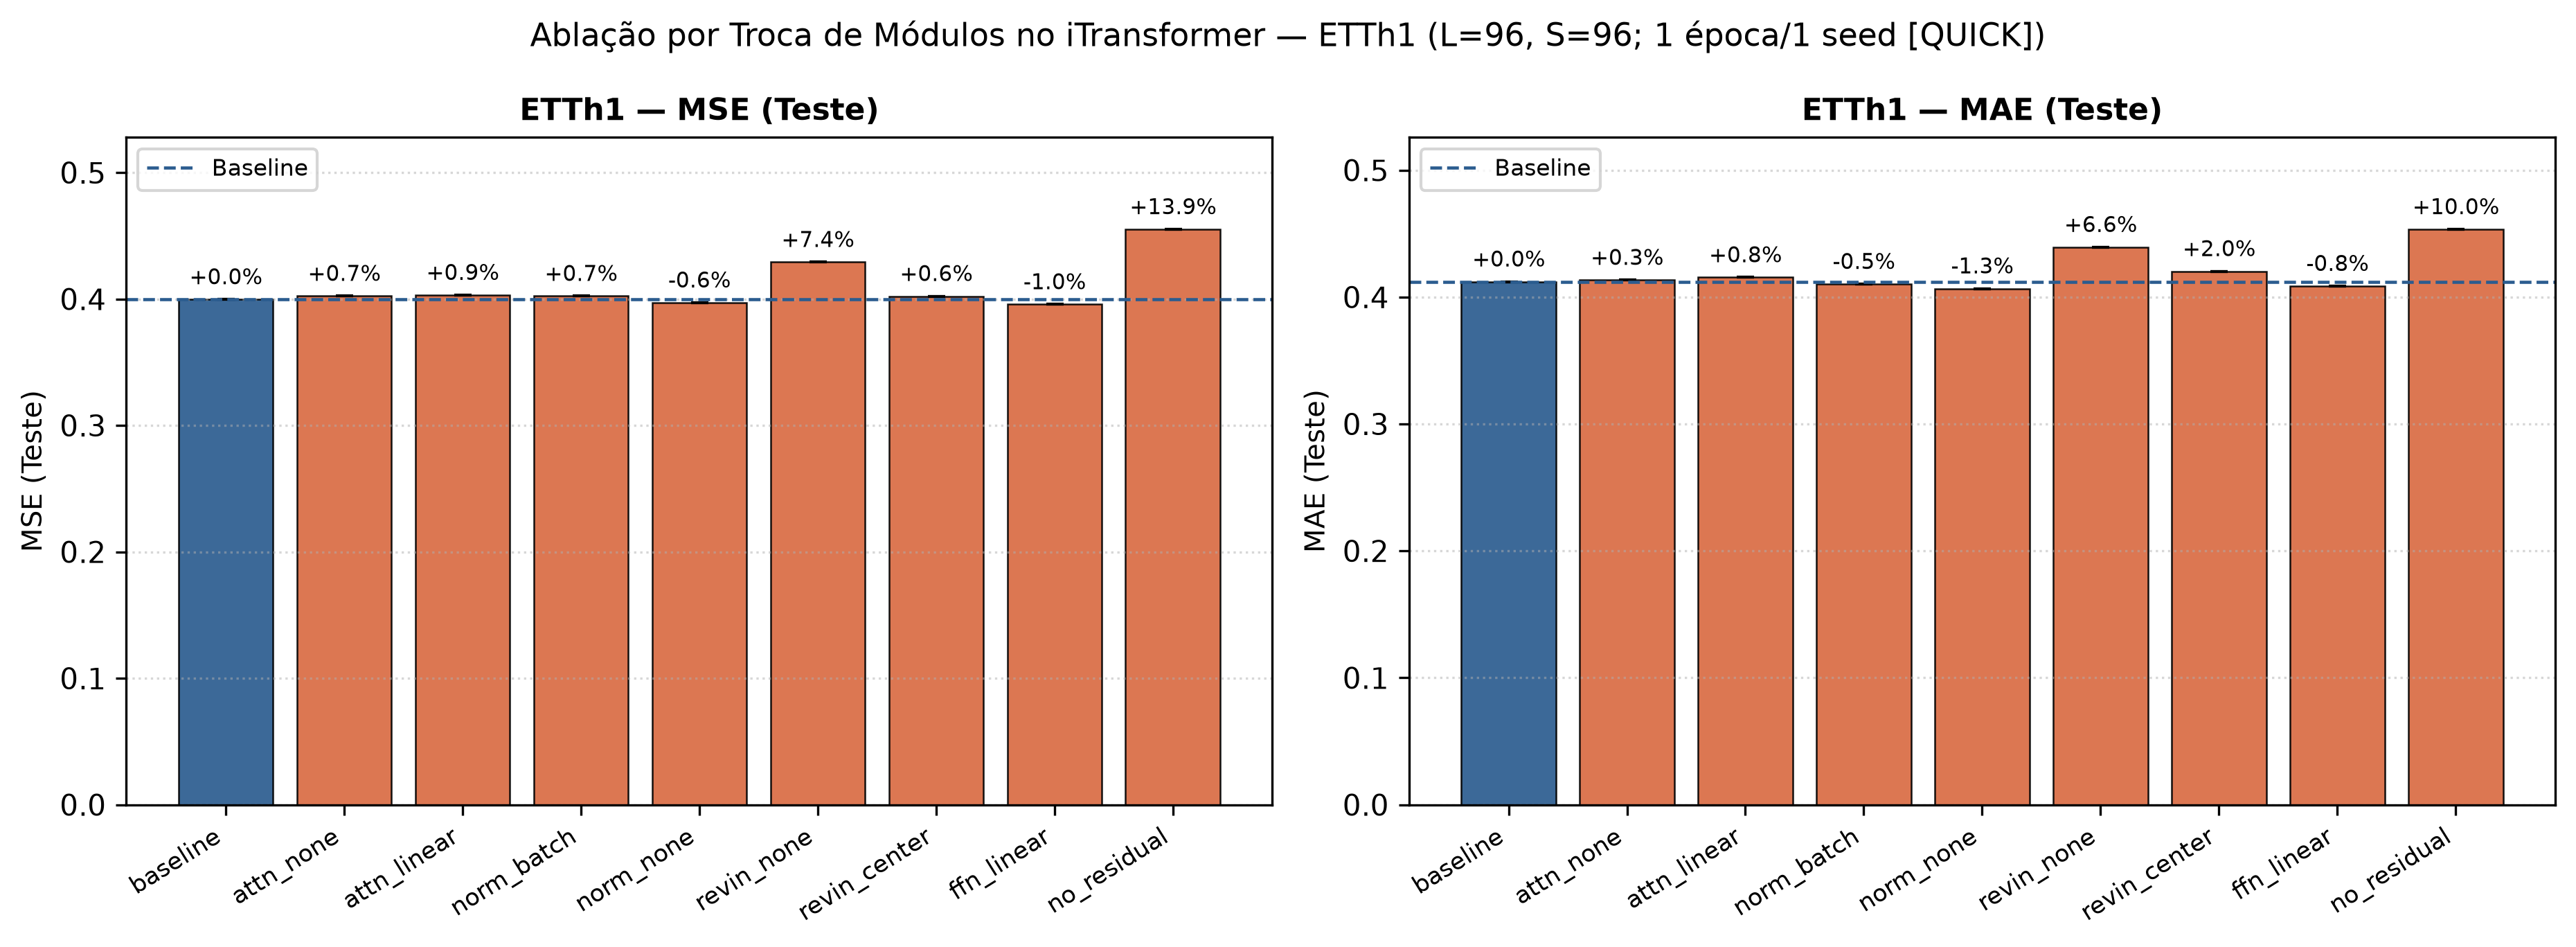

Gráfico salvo em: C:\Users\oandr\Documentos computador\t_final_ml\ablation_outputs\ablation_ETTh1.png


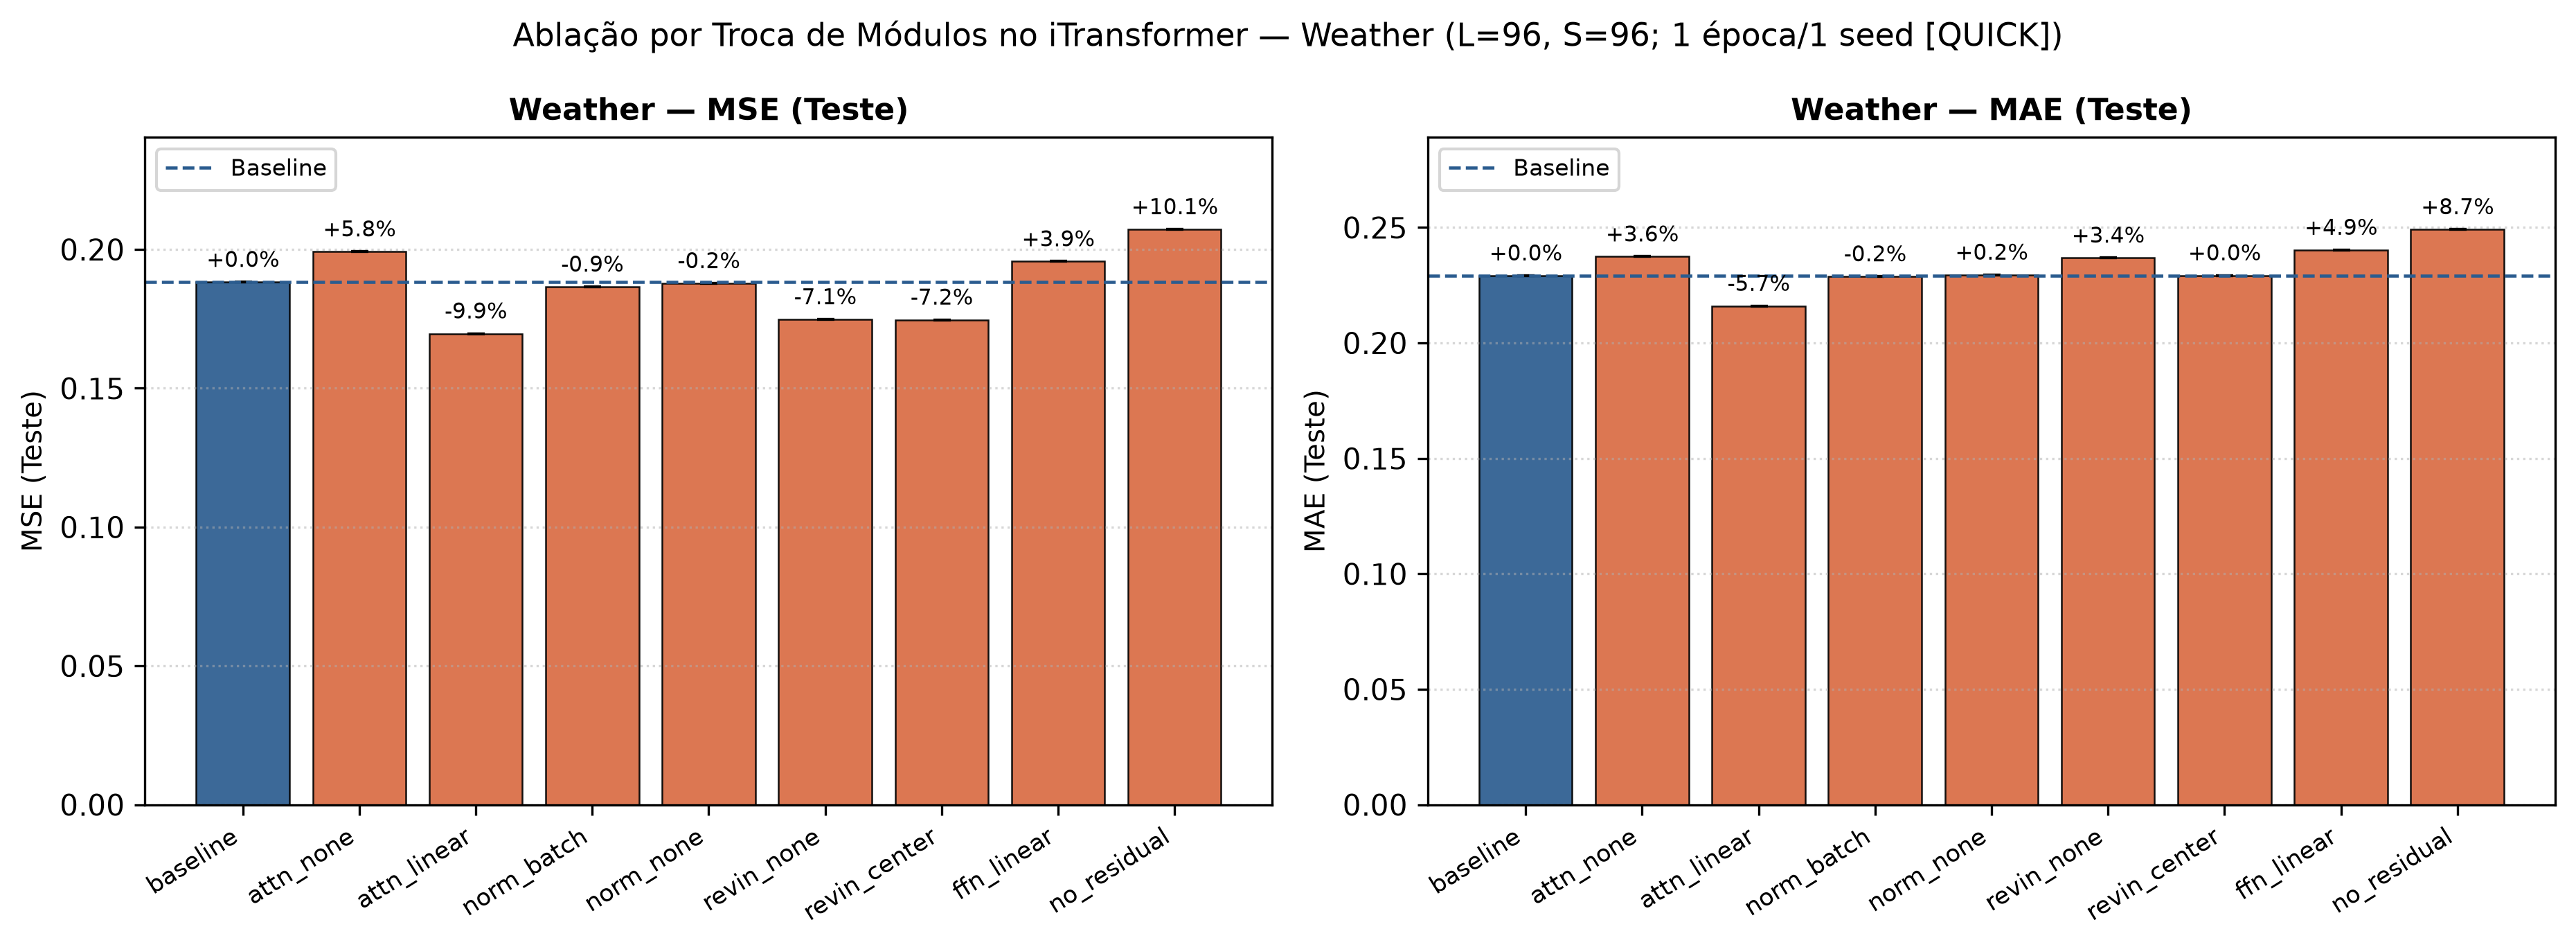

Gráfico salvo em: C:\Users\oandr\Documentos computador\t_final_ml\ablation_outputs\ablation_Weather.png
Tabela LaTeX exportada em: C:\Users\oandr\Documentos computador\t_final_ml\ablation_outputs\tabela_resultados.tex

% Gerado automaticamente por iTransformer_ablation.ipynb
\begin{table*}[t]
\centering
\caption{Resultados da troca de módulos no iTransformer ($L=96$, $S=96$, smoke test: 1 época, 1 semente). $^\dagger$Indica diferença menor que o desvio-padrão do \texttt{baseline} (dentro da faixa de ruído).}
\label{tab:resultados}
\scriptsize
\setlength{\tabcolsep}{3.2pt}
\begin{tabular}{llcccccccc}
\toprule
 & & \multicolumn{4}{c}{\textbf{ETTh1} ($N=7$, $E=256$, $L_{\text{enc}}=2$)} & \multicolumn{4}{c}{\textbf{Weather} ($N=21$, $E=512$, $L_{\text{enc}}=3$)} \\
\cmidrule(lr){3-6}\cmidrule(lr){7-10}
\textbf{Variante} & \textbf{Família} & \textbf{MSE} & \textbf{MAE} & \textbf{Params} & \textbf{s/ép (ép)} & \textbf{MSE} & \textbf{MAE} & \textbf{Params} & \textbf{s/ép (ép)} \\
\midrule
\t

In [7]:
# === CÉLULA 7: Análise Estatística, Gráficos (300 dpi), CSV e Tabela LaTeX ===
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

assert RESULTS_FILE.exists(), f"Arquivo de resultados não encontrado: {RESULTS_FILE}"

rows = []
with open(RESULTS_FILE, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if line:
            rows.append(json.loads(line))

df_raw = pd.DataFrame(rows)
# Remove eventuais duplicatas mantendo a execução mais recente
df_raw = df_raw.drop_duplicates(subset=["dataset", "variant", "seed"], keep="last").reset_index(drop=True)
print(f"Registros carregados: {len(df_raw)} (modo={'QUICK' if QUICK else 'COMPLETO'})")

summary_rows = []
for ds_name in ["ETTh1", "Weather"]:
    sub_ds = df_raw[df_raw["dataset"] == ds_name]
    if sub_ds.empty:
        continue
    base_sub = sub_ds[sub_ds["variant"] == "baseline"]
    base_mse_mean = base_sub["mse"].mean()
    base_mse_std = base_sub["mse"].std(ddof=1) if len(base_sub) > 1 else np.nan
    base_mae_mean = base_sub["mae"].mean()
    base_mae_std = base_sub["mae"].std(ddof=1) if len(base_sub) > 1 else np.nan

    for var_id in VARIANT_ORDER:
        vsub = sub_ds[sub_ds["variant"] == var_id]
        if vsub.empty:
            continue
        n_seeds = len(vsub)
        mse_mean = vsub["mse"].mean()
        mse_std = vsub["mse"].std(ddof=1) if n_seeds > 1 else 0.0
        mae_mean = vsub["mae"].mean()
        mae_std = vsub["mae"].std(ddof=1) if n_seeds > 1 else 0.0

        delta_mse_pct = (mse_mean - base_mse_mean) / base_mse_mean * 100.0
        delta_mae_pct = (mae_mean - base_mae_mean) / base_mae_mean * 100.0

        if var_id == "baseline" or np.isnan(base_mse_std):
            mse_noise = False
            mae_noise = False
        else:
            mse_noise = abs(mse_mean - base_mse_mean) < base_mse_std
            mae_noise = abs(mae_mean - base_mae_mean) < base_mae_std

        summary_rows.append({
            "dataset": ds_name,
            "variant": var_id,
            "family": VARIANT_FAMILY[var_id],
            "n_seeds": n_seeds,
            "mse_mean": mse_mean,
            "mse_std": mse_std,
            "delta_mse_pct": delta_mse_pct,
            "mse_within_noise": mse_noise,
            "mae_mean": mae_mean,
            "mae_std": mae_std,
            "delta_mae_pct": delta_mae_pct,
            "mae_within_noise": mae_noise,
            "n_params": int(vsub["n_params"].iloc[-1]),
            "epoch_time_s": vsub["avg_epoch_time"].mean(),
            "epochs_mean": vsub["epochs_run"].mean(),
        })

df_sum = pd.DataFrame(summary_rows)

# Exibe tabelas formatadas por base
for ds_name in ["ETTh1", "Weather"]:
    part = df_sum[df_sum["dataset"] == ds_name].copy()
    if part.empty:
        continue
    print(f"\n=== Resumo: {ds_name} (L=96, S=96) ===")
    disp = pd.DataFrame({
        "Variante": part["variant"],
        "Família": part["family"],
        "MSE (média ± dp)": [
            f"{m:.4f} ± {s:.4f}" + (" [ruído]" if n else "")
            for m, s, n in zip(part["mse_mean"], part["mse_std"], part["mse_within_noise"])
        ],
        "ΔMSE (%)": [f"{d:+.2f}%" for d in part["delta_mse_pct"]],
        "MAE (média ± dp)": [
            f"{m:.4f} ± {s:.4f}" + (" [ruído]" if n else "")
            for m, s, n in zip(part["mae_mean"], part["mae_std"], part["mae_within_noise"])
        ],
        "ΔMAE (%)": [f"{d:+.2f}%" for d in part["delta_mae_pct"]],
        "Params": [f"{p:,}" for p in part["n_params"]],
        "Tempo/ép (s)": [f"{t:.2f}" for t in part["epoch_time_s"]],
        "Épocas": [f"{e:.1f}" for e in part["epochs_mean"]],
    })
    display(disp)

# Exporta CSV
csv_path = OUT_DIR / "summary_results.csv"
df_sum.to_csv(csv_path, index=False)
print(f"\nCSV exportado em: {csv_path}")

# Gráficos de barras com barras de erro por base (PNG 300 dpi)
for ds_name in ["ETTh1", "Weather"]:
    part = df_sum[df_sum["dataset"] == ds_name].set_index("variant").reindex(VARIANT_ORDER).dropna(subset=["mse_mean"])
    if part.empty:
        continue

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), dpi=300)
    x = np.arange(len(part))
    labels = list(part.index)

    for ax, metric_key, title in [
        (axes[0], "mse", "MSE (Teste)"),
        (axes[1], "mae", "MAE (Teste)"),
    ]:
        means = part[f"{metric_key}_mean"].values
        stds = part[f"{metric_key}_std"].values
        deltas = part[f"delta_{metric_key}_pct"].values
        noises = part[f"{metric_key}_within_noise"].values
        base_m = part.loc["baseline", f"{metric_key}_mean"]
        base_s = part.loc["baseline", f"{metric_key}_std"]

        colors = []
        for lbl, is_noise in zip(labels, noises):
            if lbl == "baseline":
                colors.append("#2b5c8f")
            elif is_noise:
                colors.append("#9aa5b1")  # diferença < desvio do baseline (ruído)
            else:
                colors.append("#d96b43")

        bars = ax.bar(x, means, yerr=stds, capsize=3, color=colors, edgecolor="black", linewidth=0.6, alpha=0.92)
        ax.axhline(base_m, color="#2b5c8f", linestyle="--", linewidth=1.1, label="Baseline")
        if base_s > 0:
            ax.axhspan(base_m - base_s, base_m + base_s, color="#2b5c8f", alpha=0.12, label="±1 dp baseline")

        ymax = max(means + stds) * 1.16
        ax.set_ylim(0, ymax)
        for bar, d, s in zip(bars, deltas, stds):
            h = bar.get_height() + s
            ax.text(
                bar.get_x() + bar.get_width() / 2.0,
                h + ymax * 0.015,
                f"{d:+.1f}%",
                ha="center",
                va="bottom",
                fontsize=7.5,
                rotation=0,
            )

        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=32, ha="right", fontsize=8.5)
        ax.set_ylabel(title, fontsize=9.5)
        ax.set_title(f"{ds_name} — {title}", fontsize=10.5, fontweight="bold")
        ax.grid(axis="y", linestyle=":", alpha=0.5)
        ax.legend(fontsize=8, loc="upper left")

    fig.suptitle(
        f"Ablação por Troca de Módulos no iTransformer — {ds_name} (L=96, S=96; "
        f"{'1 época/1 seed [QUICK]' if QUICK else 'média ± dp em 3 seeds'})",
        fontsize=11,
    )
    plt.tight_layout()
    png_path = OUT_DIR / f"ablation_{ds_name}.png"
    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Gráfico salvo em: {png_path}")

# Exporta tabela LaTeX compacta (booktabs, duas colunas IEEE) -> tabela_resultados.tex
def fmt_params(n):
    if n >= 1_000_000:
        return f"{n/1e6:.2f}M"
    return f"{n/1e3:.0f}k"


def fmt_metric(row, key, is_best):
    m = row[f"{key}_mean"]
    s = row[f"{key}_std"]
    noise = row[f"{key}_within_noise"]
    txt = f"{m:.3f}$\\pm${s:.3f}" if row["n_seeds"] > 1 else f"{m:.3f}"
    if is_best:
        txt = f"\\textbf{{{txt}}}"
    if noise:
        txt += "$^\\dagger$"
    return txt


ett_map = df_sum[df_sum["dataset"] == "ETTh1"].set_index("variant")
wea_map = df_sum[df_sum["dataset"] == "Weather"].set_index("variant")
best_ett_mse = ett_map["mse_mean"].idxmin() if not ett_map.empty else None
best_ett_mae = ett_map["mae_mean"].idxmin() if not ett_map.empty else None
best_wea_mse = wea_map["mse_mean"].idxmin() if not wea_map.empty else None
best_wea_mae = wea_map["mae_mean"].idxmin() if not wea_map.empty else None

tex_lines = [
    "% Gerado automaticamente por iTransformer_ablation.ipynb",
    "\\begin{table*}[t]",
    "\\centering",
    "\\caption{Resultados da troca de módulos no iTransformer ($L=96$, $S=96$, "
    + ("smoke test: 1 época, 1 semente" if QUICK else "média $\\pm$ desvio em 3 sementes")
    + "). $^\\dagger$Indica diferença menor que o desvio-padrão do \\texttt{baseline} (dentro da faixa de ruído).}",
    "\\label{tab:resultados}",
    "\\scriptsize",
    "\\setlength{\\tabcolsep}{3.2pt}",
    "\\begin{tabular}{llcccccccc}",
    "\\toprule",
    " & & \\multicolumn{4}{c}{\\textbf{ETTh1} ($N=7$, $E=256$, $L_{\\text{enc}}=2$)} & "
    "\\multicolumn{4}{c}{\\textbf{Weather} ($N=21$, $E=512$, $L_{\\text{enc}}=3$)} \\\\",
    "\\cmidrule(lr){3-6}\\cmidrule(lr){7-10}",
    "\\textbf{Variante} & \\textbf{Família} & \\textbf{MSE} & \\textbf{MAE} & \\textbf{Params} & \\textbf{s/ép (ép)} & "
    "\\textbf{MSE} & \\textbf{MAE} & \\textbf{Params} & \\textbf{s/ép (ép)} \\\\",
    "\\midrule",
]

for var_id, fam, _ in VARIANTS:
    v_tex = "\\texttt{" + var_id.replace("_", "\\_") + "}"
    fam_tex = "---" if var_id == "baseline" else fam

    if var_id in ett_map.index:
        r = ett_map.loc[var_id]
        e_cols = [
            fmt_metric(r, "mse", var_id == best_ett_mse),
            fmt_metric(r, "mae", var_id == best_ett_mae),
            fmt_params(r["n_params"]),
            f"{r['epoch_time_s']:.1f} ({r['epochs_mean']:.1f})",
        ]
    else:
        e_cols = ["--", "--", "--", "--"]

    if var_id in wea_map.index:
        r = wea_map.loc[var_id]
        w_cols = [
            fmt_metric(r, "mse", var_id == best_wea_mse),
            fmt_metric(r, "mae", var_id == best_wea_mae),
            fmt_params(r["n_params"]),
            f"{r['epoch_time_s']:.1f} ({r['epochs_mean']:.1f})",
        ]
    else:
        w_cols = ["--", "--", "--", "--"]

    tex_lines.append(" & ".join([v_tex, fam_tex] + e_cols + w_cols) + " \\\\")

tex_lines += [
    "\\bottomrule",
    "\\end{tabular}",
    "\\vspace{-4pt}",
    "\\end{table*}",
]

tex_path = OUT_DIR / "tabela_resultados.tex"
tex_path.write_text("\n".join(tex_lines) + "\n", encoding="utf-8")
print(f"Tabela LaTeX exportada em: {tex_path}\n")
print("\n".join(tex_lines))


In [8]:
# === CÉLULA 8: Comparação do Baseline com o Artigo Original (ICLR 2024, S=96) ===
import pandas as pd
from IPython.display import display

# Valores de referência do artigo iTransformer (ICLR 2024, Tabela de resultados completos, pred_len=96).
# Obs.: confirme na Tabela 1 / Apêndice do PDF oficial antes da entrega final.
PAPER_REF = {
    "ETTh1":   {"paper_mse": 0.386, "paper_mae": 0.405},
    "Weather": {"paper_mse": 0.174, "paper_mae": 0.214},
}

comp_rows = []
for ds_name, ref in PAPER_REF.items():
    sub = df_sum[(df_sum["dataset"] == ds_name) & (df_sum["variant"] == "baseline")]
    if sub.empty:
        continue
    r = sub.iloc[0]
    diff_mse = r["mse_mean"] - ref["paper_mse"]
    diff_mae = r["mae_mean"] - ref["paper_mae"]
    comp_rows.append({
        "Base": ds_name,
        "Artigo MSE": ref["paper_mse"],
        "Nosso Baseline MSE": f"{r['mse_mean']:.4f} ± {r['mse_std']:.4f}",
        "Diff MSE": f"{diff_mse:+.4f} ({diff_mse / ref['paper_mse'] * 100:+.2f}%)",
        "Artigo MAE": ref["paper_mae"],
        "Nosso Baseline MAE": f"{r['mae_mean']:.4f} ± {r['mae_std']:.4f}",
        "Diff MAE": f"{diff_mae:+.4f} ({diff_mae / ref['paper_mae'] * 100:+.2f}%)",
    })

df_comp = pd.DataFrame(comp_rows)
display(df_comp)

if QUICK:
    print(
        "\n[NOTA] Você está em modo QUICK (1 época, 1 seed). O baseline ainda não convergiu totalmente; "
        "a comparação justa com o artigo deve ser feita com QUICK = False (10 épocas, patience=3, 3 seeds)."
    )
else:
    print(
        "\n[COMENTÁRIO SOBRE DIFERENÇAS VS. ARTIGO]\n"
        "Pequenas diferenças entre nosso baseline e a tabela do artigo são esperadas por:\n"
        "1. Avaliação em 3 seeds (2021, 2022, 2023) em vez de uma única seed fixa (2023 no run.py original).\n"
        "2. Versões mais recentes de PyTorch/CUDA/cuDNN em relação ao ambiente original (torch==2.0.0).\n"
        "3. Não determinismo numérico de kernels em GPU.\n"
        "Obs.: pular a avaliação de teste a cada época (--skip_test_during_train) NÃO altera o treino "
        "nem o early stopping, pois o early stopping monitora exclusivamente a perda de validação."
    )


,Base,Artigo MSE,Nosso Baseline MSE,Diff MSE,Artigo MAE,Nosso Baseline MAE,Diff MAE
0,ETTh1,0.386,0.3996 ± 0.0000,+0.0136 (+3.53%),0.405,0.4121 ± 0.0000,+0.0071 (+1.75%)
1,Weather,0.174,0.1882 ± 0.0000,+0.0142 (+8.18%),0.214,0.2291 ± 0.0000,+0.0151 (+7.08%)



[NOTA] Você está em modo QUICK (1 época, 1 seed). O baseline ainda não convergiu totalmente; a comparação justa com o artigo deve ser feita com QUICK = False (10 épocas, patience=3, 3 seeds).
